In [1]:
# # ===== CELL 1: GPU check + install dependencies =====
# import subprocess, sys

# # 1) GPU check
# print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

# # 2) Install (torch is preinstalled on Colab, so we don't touch it)
# !pip install -q -U \
#     langgraph langchain-core langchain-groq langsmith \
#     transformers accelerate bitsandbytes \
#     sentence-transformers faiss-cpu \
#     pandas numpy tqdm gradio

# # 3) Verify versions
# import torch, transformers, langgraph, importlib.metadata as md
# print("torch        :", torch.__version__, "| CUDA available:", torch.cuda.is_available())
# if torch.cuda.is_available():
#     print("GPU          :", torch.cuda.get_device_name(0))
#     print("VRAM (GB)    :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
# print("transformers :", transformers.__version__)
# print("langgraph    :", md.version("langgraph"))
# print("langsmith    :", md.version("langsmith"))
# print("bitsandbytes :", md.version("bitsandbytes"))
# print("faiss-cpu    :", md.version("faiss-cpu"))

In [2]:
# ===== CELL 2 (fixed): Load API keys + test Groq and LangSmith =====
import os, time
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"] = userdata.get("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "agentic-llm-gateway"

from langchain_groq import ChatGroq

LARGE_MODEL    = "openai/gpt-oss-120b"
FALLBACK_MODEL = "openai/gpt-oss-20b"   # used later for circuit-breaker fallback

large_llm = ChatGroq(model=LARGE_MODEL, temperature=0, timeout=30,
                     max_retries=0, reasoning_effort="low")

t0 = time.perf_counter()
resp = large_llm.invoke("What is the capital of India? Answer in one short sentence.")
latency = time.perf_counter() - t0

print("Groq answer :", resp.content)
print("Latency (s) :", round(latency, 2))
print("Token usage :", resp.response_metadata.get("token_usage"))

from langsmith import Client
client = Client()
print("LangSmith OK, projects:", [p.name for p in client.list_projects(limit=5)])

Groq answer : New Delhi is the capital of India.
Latency (s) : 0.54
Token usage : {'completion_tokens': 22, 'prompt_tokens': 84, 'total_tokens': 106, 'completion_time': 0.045989409, 'completion_tokens_details': {'reasoning_tokens': 5}, 'prompt_time': 0.013911005, 'prompt_tokens_details': None, 'queue_time': 0.178521949, 'total_time': 0.059900414}
LangSmith OK, projects: ['agentic-llm-gateway']


In [3]:
# ===== CELL 3: Load small LLM (4-bit) + generation helper =====
import time, torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

SMALL_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(SMALL_MODEL)
small_model = AutoModelForCausalLM.from_pretrained(
    SMALL_MODEL,
    quantization_config=bnb_config,
    device_map="cuda:0",
    dtype=torch.float16,
)
small_model.eval()

print("VRAM used (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

def small_generate(prompt: str, system: str = "You are a helpful assistant.",
                   max_new_tokens: int = 256):
    """Returns dict: text, prompt_tokens, completion_tokens, latency_s"""
    messages = [{"role": "system", "content": system},
                {"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to("cuda:0")

    torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        out = small_model.generate(**inputs, max_new_tokens=max_new_tokens,
                                   do_sample=False, pad_token_id=tokenizer.eos_token_id)
    torch.cuda.synchronize()
    latency = time.perf_counter() - t0

    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return {
        "text": tokenizer.decode(new_tokens, skip_special_tokens=True).strip(),
        "prompt_tokens": int(inputs["input_ids"].shape[1]),
        "completion_tokens": int(len(new_tokens)),
        "latency_s": round(latency, 3),
    }

# Warm-up (first call is slow), then a timed test
small_generate("Hi", max_new_tokens=8)
r = small_generate("What is the capital of India? Answer in one short sentence.")
print(r)
print("Tokens/sec:", round(r["completion_tokens"] / r["latency_s"], 1))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

VRAM used (GB): 1.15
{'text': 'The capital of India is New Delhi.', 'prompt_tokens': 32, 'completion_tokens': 9, 'latency_s': 1.314}
Tokens/sec: 6.8


In [4]:
# ===== CELL 4: Create document corpus (NimbusDesk knowledge base) =====
import os, json
os.makedirs("/content/data", exist_ok=True)

DOCS = [
 {"id": "refund_policy", "title": "Refund Policy", "text":
  "Monthly plans are not refundable, except for billing errors reported within 7 days of the charge. "
  "Annual plans: customers get a full refund if they cancel within 30 days of purchase. After 30 days, no refund is given, "
  "except when the cancellation is caused by service downtime that breached the SLA. In that case the customer receives a prorated refund "
  "for unused full months, minus a 15% administrative fee. Approved refunds are returned to the original payment method within 7 to 10 business days. "
  "Enterprise refunds follow the terms of the signed contract."},
 {"id": "pricing_plans", "title": "Pricing and Plans", "text":
  "NimbusDesk has three plans. Starter costs Rs 999 per user per month and supports up to 5 users. Pro costs Rs 2,499 per user per month and supports up to 100 users. "
  "Enterprise has custom pricing and unlimited users. Paying annually gives a 20% discount over monthly billing. Every new account gets a 14-day free trial, and no credit card is required. "
  "Extra storage can be added as an add-on at Rs 500 per 100 GB per month. Prices exclude GST."},
 {"id": "sla_uptime", "title": "SLA and Uptime", "text":
  "Guaranteed monthly uptime is 99.5% for Starter, 99.9% for Pro and 99.99% for Enterprise. If uptime falls below the guarantee but stays at or above 99.0%, the customer gets a 10% service credit. "
  "Below 99.0% the credit is 25%, and below 95.0% the credit is 50%. Credits must be claimed within 30 days of the incident by contacting support. "
  "Scheduled maintenance takes place every Sunday from 02:00 to 04:00 IST and is excluded from uptime calculations."},
 {"id": "support", "title": "Customer Support", "text":
  "Starter customers get email support only, with a first response within 48 hours. Pro customers get email and live chat, available Monday to Saturday from 9 AM to 9 PM IST, "
  "with a first response within 4 hours. Enterprise customers get 24x7 phone support, a dedicated account manager, and a 1-hour first response for critical issues. "
  "Critical issue means the product is completely unavailable for the customer."},
 {"id": "data_retention", "title": "Data Retention and Deletion", "text":
  "Deleted records stay in backups for 35 days and are then permanently removed. After an account is cancelled, customers have 60 days to export their data, after which all data is permanently deleted. "
  "Audit logs are kept for 3 months on Starter, 12 months on Pro, and 36 months on Enterprise."},
 {"id": "security", "title": "Security and Compliance", "text":
  "Data is encrypted with AES-256 at rest and TLS 1.3 in transit. NimbusDesk is SOC 2 Type II and ISO 27001 certified. Two-factor authentication is mandatory for all admin accounts on every plan. "
  "SAML single sign-on is available only on the Enterprise plan. Independent penetration tests are done once a year. Primary data is hosted in the Mumbai region, with disaster recovery in Hyderabad."},
 {"id": "api_limits", "title": "API Limits", "text":
  "API rate limits are 60 requests per minute on Starter, 600 requests per minute on Pro, and 6,000 requests per minute on Enterprise. When the limit is exceeded the API returns HTTP 429 with a Retry-After header. "
  "The maximum request payload is 5 MB. Failed webhooks are retried 5 times with exponential backoff. API keys should be rotated every 90 days."},
 {"id": "cancellation", "title": "Cancellation and Renewal", "text":
  "Customers can cancel at any time from Settings, then Billing. Monthly plans end at the close of the current billing cycle. Annual plans renew automatically, and a reminder email is sent 14 days before renewal. "
  "Plan downgrades take effect only at renewal. A cancelled account can be reactivated within 60 days with all its data intact."},
 {"id": "billing_gst", "title": "Billing and GST", "text":
  "An 18% GST is added to every invoice for customers in India. Invoices are generated on the first day of each billing cycle. Accepted payment methods are UPI, credit and debit cards, and net banking. "
  "A failed payment is retried 3 times over 7 days, and the account is suspended on day 8 if payment is still unsuccessful. There is no late fee. Customers can add their GSTIN under Billing settings."},
 {"id": "integrations", "title": "Integrations", "text":
  "NimbusDesk integrates with Slack, Microsoft Teams, Jira, Salesforce and Zapier. Jira and Slack are available on all plans. Microsoft Teams and Salesforce require the Pro plan or higher. "
  "Custom integrations can be built using the REST API."},
 {"id": "onboarding", "title": "Onboarding and Data Import", "text":
  "Starter customers use self-serve onboarding. Pro customers receive 2 onboarding sessions of 60 minutes each. Enterprise customers get a guided 4-week onboarding that includes data migration. "
  "CSV data import supports up to 100,000 rows per file."},
 {"id": "user_management", "title": "User Management", "text":
  "NimbusDesk has four roles: Admin, Manager, Member and Viewer. Viewer seats are free and unlimited on every plan. A paid seat can be reassigned to another person only once every 30 days. "
  "User limits are 5 on Starter, 100 on Pro, and unlimited on Enterprise."},
]

with open("/content/data/docs.json", "w") as f:
    json.dump(DOCS, f, indent=2)

total_words = sum(len(d["text"].split()) for d in DOCS)
print(f"Saved {len(DOCS)} documents -> /content/data/docs.json")
print(f"Total words: {total_words} | Avg words/doc: {total_words // len(DOCS)}")
for d in DOCS:
    print(f"  - {d['id']:<16} {len(d['text'].split()):>3} words")

Saved 12 documents -> /content/data/docs.json
Total words: 738 | Avg words/doc: 61
  - refund_policy     93 words
  - pricing_plans     81 words
  - sla_uptime        76 words
  - support           67 words
  - data_retention    51 words
  - security          64 words
  - api_limits        61 words
  - cancellation      56 words
  - billing_gst       71 words
  - integrations      37 words
  - onboarding        36 words
  - user_management   45 words


In [5]:
# ===== CELL 5: Test set part 1 -> easy (40) + hard (30) =====
import json

EASY = [
 ("What is the capital of India?", "New Delhi"),
 ("Who wrote the play Romeo and Juliet?", "William Shakespeare"),
 ("What is the chemical symbol for gold?", "Au"),
 ("How many days are in a leap year?", "366"),
 ("Which planet is known as the Red Planet?", "Mars"),
 ("What is the largest ocean on Earth?", "Pacific Ocean"),
 ("Who was the first Prime Minister of India?", "Jawaharlal Nehru"),
 ("Which gas do plants absorb from the air for photosynthesis?", "Carbon dioxide"),
 ("What is the boiling point of water in Celsius at sea level?", "100"),
 ("Which language is primarily used for styling web pages?", "CSS"),
 ("What does CPU stand for?", "Central Processing Unit"),
 ("Who painted the Mona Lisa?", "Leonardo da Vinci"),
 ("What is the national animal of India?", "Tiger"),
 ("In which year did India gain independence?", "1947"),
 ("What is the largest planet in our solar system?", "Jupiter"),
 ("What does HTML stand for?", "HyperText Markup Language"),
 ("Who discovered penicillin?", "Alexander Fleming"),
 ("What is the freezing point of water in Fahrenheit?", "32"),
 ("Which organ pumps blood through the human body?", "Heart"),
 ("What is the capital of France?", "Paris"),
 ("What is the currency of Japan?", "Yen"),
 ("Who invented the telephone?", "Alexander Graham Bell"),
 ("What is the hardest natural substance?", "Diamond"),
 ("Which continent is Egypt in?", "Africa"),
 ("What does RAM stand for?", "Random Access Memory"),
 ("Which festival of lights is celebrated in India?", "Diwali"),
 ("What is the smallest prime number?", "2"),
 ("Which metal is liquid at room temperature?", "Mercury"),
 ("What is the opposite of the word 'ancient'?", "Modern"),
 ("Who is known as the Father of the Nation in India?", "Mahatma Gandhi"),
 ("What is the largest mammal on Earth?", "Blue whale"),
 ("What does HTTP stand for?", "HyperText Transfer Protocol"),
 ("Which planet is closest to the Sun?", "Mercury"),
 ("How many continents are there?", "7"),
 ("What is the main language spoken in Brazil?", "Portuguese"),
 ("What is H2O commonly called?", "Water"),
 ("Which sport is played at Wimbledon?", "Tennis"),
 ("What is the capital of Japan?", "Tokyo"),
 ("Which programming language is named after a snake?", "Python"),
 ("What is the process by which liquid water turns into vapor called?", "Evaporation"),
]

HARD = [
 ("Explain the difference between a process and a thread, and give one case where multithreading hurts performance.",
  "Processes have separate memory; threads share memory within a process. Multithreading can hurt via lock contention, context switching overhead, or the Python GIL for CPU-bound work."),
 ("Why does gradient descent with a very large learning rate fail to converge?",
  "Steps overshoot the minimum, so the loss oscillates or diverges."),
 ("Compare B-tree and hash indexes and say when each is better.",
  "B-tree supports range queries and ordering; hash index is faster for exact equality lookups but cannot do ranges."),
 ("Explain the CAP theorem.",
  "During a network partition a distributed system must choose between consistency and availability; partition tolerance is required."),
 ("What is the time complexity of binary search and why?",
  "O(log n) because each step halves the search space; the array must be sorted."),
 ("Why does quantizing an LLM to 4-bit reduce memory but possibly reduce accuracy?",
  "Weights are stored in fewer bits (about 4x smaller than fp16), but rounding loses precision, which can reduce accuracy."),
 ("What is the difference between L1 and L2 regularization?",
  "L1 encourages sparse weights (feature selection); L2 shrinks weights smoothly toward zero without making them exactly zero."),
 ("What are the four necessary conditions for a deadlock?",
  "Mutual exclusion, hold and wait, no preemption, circular wait."),
 ("How does attention differ from recurrence for handling long sequences?",
  "Attention connects all positions directly and is parallelizable, but costs quadratic compute; RNNs process sequentially and suffer vanishing gradients on long sequences."),
 ("Why is a KV cache used in LLM inference?",
  "It stores the keys and values of previous tokens so they are not recomputed at each step, trading memory for speed."),
 ("Explain precision versus recall and when recall should be prioritized.",
  "Precision = TP/(TP+FP); recall = TP/(TP+FN). Prioritize recall when missing a positive is costly, such as disease screening."),
 ("Explain eventual consistency with an example.",
  "Replicas converge to the same value if no new updates arrive; for example DNS propagation or social media like counts."),
 ("What is overfitting and what are three ways to reduce it?",
  "The model memorizes training data and generalizes poorly. Remedies: more data, regularization, dropout, early stopping, cross-validation."),
 ("Explain the bias-variance tradeoff.",
  "High bias causes underfitting and high variance causes overfitting; increasing model complexity lowers bias but raises variance."),
 ("Why use the circuit breaker pattern in microservices?",
  "It stops calls to a failing service, fails fast, prevents cascading failures, and probes for recovery (half-open state)."),
 ("Explain TCP versus UDP and when to use UDP.",
  "TCP is connection-oriented, reliable and ordered; UDP is connectionless and low-latency without guarantees. Use UDP for video, gaming, DNS."),
 ("Compare monolith and microservices architectures with one trade-off each.",
  "Monolith is simple to deploy but scales as one unit; microservices scale and deploy independently but add operational and network complexity."),
 ("What is a hash collision and how can it be handled?",
  "Two keys map to the same bucket. Handle with chaining or open addressing."),
 ("Why can retrieval-augmented generation reduce hallucinations and when does it still fail?",
  "It grounds answers in retrieved documents; it still fails when retrieval misses relevant context or the model ignores the context."),
 ("Differentiate supervised, unsupervised and reinforcement learning.",
  "Supervised uses labeled data; unsupervised finds structure in unlabeled data; reinforcement learns from rewards by interacting with an environment."),
 ("Why is softmax used in the output layer of a classifier?",
  "It converts logits into a probability distribution that sums to 1."),
 ("What are the trade-offs between a large and a small LLM in production?",
  "Large models give higher quality but cost more and are slower; small models are cheaper and faster but weaker at reasoning and more prone to hallucination."),
 ("Explain the ACID properties of database transactions.",
  "Atomicity, Consistency, Isolation, Durability."),
 ("Why does batch normalization speed up training?",
  "It stabilizes layer input distributions, allowing higher learning rates and faster, more stable convergence."),
 ("Explain the difference between latency and throughput.",
  "Latency is time per request; throughput is requests handled per unit time. Batching can raise throughput while increasing latency."),
 ("What is the difference between p50 and p95 latency and why track p95?",
  "p50 is the median; p95 is the 95th percentile. p95 exposes tail latency that affects a meaningful share of users."),
 ("Explain how a Bloom filter works and its main limitation.",
  "A bit array with multiple hash functions; it can give false positives but never false negatives, and basic versions cannot delete items."),
 ("Why is the Python GIL a problem for CPU-bound multithreading?",
  "Only one thread executes Python bytecode at a time, so threads do not run CPU-bound work in parallel; use multiprocessing instead."),
 ("Explain the difference between REST and gRPC.",
  "REST typically uses HTTP with JSON text; gRPC uses HTTP/2 with binary protobuf and supports streaming, with lower overhead."),
 ("What is semantic caching for LLM applications and what is one risk?",
  "It returns saved answers for queries with similar embeddings; the risk is a false hit that returns a wrong answer to a different question."),
]

rows = []
for i, (q, a) in enumerate(EASY):
    rows.append({"id": f"easy_{i:03d}", "category": "easy", "query": q, "reference": a,
                 "route": "small", "doc_ids": [], "repeat_of": None})
for i, (q, a) in enumerate(HARD):
    rows.append({"id": f"hard_{i:03d}", "category": "hard", "query": q, "reference": a,
                 "route": "large", "doc_ids": [], "repeat_of": None})

with open("/content/data/testset_part1.json", "w") as f:
    json.dump(rows, f, indent=2)

from collections import Counter
print("Saved:", len(rows), "queries ->", dict(Counter(r["category"] for r in rows)))
print("Sample easy:", rows[0]["query"], "->", rows[0]["reference"])
print("Sample hard:", rows[40]["query"])

Saved: 70 queries -> {'easy': 40, 'hard': 30}
Sample easy: What is the capital of India? -> New Delhi
Sample hard: Explain the difference between a process and a thread, and give one case where multithreading hurts performance.


In [6]:
# ===== CELL 6: Test set part 2 -> doc (50) + tool (40) + repeated (40) -> merge =====
import json, random
from collections import Counter

random.seed(42)
part1 = json.load(open("/content/data/testset_part1.json"))
easy_rows = [r for r in part1 if r["category"] == "easy"]

# ---------- DOC queries (50): (query, reference, doc_id) ----------
DOCQ = [
 ("Summarize our refund policy for annual plans.", "Full refund within 30 days of purchase; after 30 days no refund unless SLA-breaching downtime caused the cancellation, then prorated for unused full months minus a 15% admin fee; refunds take 7-10 business days.", "refund_policy"),
 ("Can I get a refund on a monthly plan?", "Monthly plans are not refundable, except billing errors reported within 7 days of the charge.", "refund_policy"),
 ("How long do refunds take to reach me?", "7 to 10 business days, to the original payment method.", "refund_policy"),
 ("What admin fee applies to a prorated annual refund?", "15%", "refund_policy"),
 ("How do refunds work for Enterprise customers?", "They follow the terms of the signed contract.", "refund_policy"),
 ("I cancelled my annual plan after 45 days. Am I eligible for a refund?", "No, unless the cancellation was caused by downtime that breached the SLA.", "refund_policy"),
 ("What does the Pro plan cost per user per month?", "Rs 2,499 per user per month", "pricing_plans"),
 ("How many users can the Starter plan support?", "Up to 5 users", "pricing_plans"),
 ("How much discount do annual plans get?", "20% discount over monthly billing", "pricing_plans"),
 ("Do I need a credit card for the free trial?", "No. The free trial lasts 14 days and needs no credit card.", "pricing_plans"),
 ("How much does extra storage cost?", "Rs 500 per 100 GB per month", "pricing_plans"),
 ("What uptime does the Enterprise plan guarantee?", "99.99%", "sla_uptime"),
 ("What service credit applies if monthly uptime is 98.5%?", "25% credit (below 99.0% but at or above 95.0%).", "sla_uptime"),
 ("Within how many days must SLA credits be claimed?", "Within 30 days of the incident.", "sla_uptime"),
 ("When is scheduled maintenance performed?", "Every Sunday from 02:00 to 04:00 IST; it is excluded from uptime calculations.", "sla_uptime"),
 ("What credit is given if uptime drops below 95%?", "50% credit", "sla_uptime"),
 ("What support do Starter customers get?", "Email support only, with a first response within 48 hours.", "support"),
 ("What are the live chat hours for Pro customers?", "Monday to Saturday, 9 AM to 9 PM IST.", "support"),
 ("What is the first response time for critical issues on Enterprise?", "1 hour", "support"),
 ("Does the Enterprise plan include phone support?", "Yes, 24x7 phone support plus a dedicated account manager.", "support"),
 ("How long do deleted records stay in backups?", "35 days, then permanently removed.", "data_retention"),
 ("How long do I have to export my data after cancelling?", "60 days; after that all data is permanently deleted.", "data_retention"),
 ("How long are audit logs kept on the Pro plan?", "12 months", "data_retention"),
 ("How long are audit logs retained for Enterprise?", "36 months", "data_retention"),
 ("What encryption does NimbusDesk use?", "AES-256 at rest and TLS 1.3 in transit.", "security"),
 ("Which plans support SAML single sign-on?", "Enterprise only", "security"),
 ("Where is customer data hosted?", "Primary hosting in Mumbai, with disaster recovery in Hyderabad.", "security"),
 ("Is two-factor authentication mandatory?", "Yes, for all admin accounts on every plan.", "security"),
 ("What is the API rate limit on the Pro plan?", "600 requests per minute", "api_limits"),
 ("What happens when the API rate limit is exceeded?", "The API returns HTTP 429 with a Retry-After header.", "api_limits"),
 ("What is the maximum API request payload size?", "5 MB", "api_limits"),
 ("How many times are failed webhooks retried?", "5 times with exponential backoff.", "api_limits"),
 ("How do I cancel my subscription?", "From Settings, then Billing.", "cancellation"),
 ("When do plan downgrades take effect?", "Only at renewal.", "cancellation"),
 ("Can I reactivate a cancelled account?", "Yes, within 60 days, with all data intact.", "cancellation"),
 ("When is the renewal reminder sent for annual plans?", "14 days before renewal.", "cancellation"),
 ("What GST is charged on invoices?", "18% GST for customers in India.", "billing_gst"),
 ("Which payment methods are accepted?", "UPI, credit and debit cards, and net banking.", "billing_gst"),
 ("What happens if my payment fails?", "It is retried 3 times over 7 days; the account is suspended on day 8 if still unpaid.", "billing_gst"),
 ("Is there a late fee for overdue payments?", "No, there is no late fee.", "billing_gst"),
 ("Where can I add my GSTIN?", "Under Billing settings.", "billing_gst"),
 ("Which integrations require the Pro plan or higher?", "Microsoft Teams and Salesforce.", "integrations"),
 ("Is Slack available on the Starter plan?", "Yes, Slack is available on all plans.", "integrations"),
 ("How can I build a custom integration?", "Using the REST API.", "integrations"),
 ("How many onboarding sessions does the Pro plan include?", "2 sessions of 60 minutes each.", "onboarding"),
 ("What is the CSV import row limit?", "Up to 100,000 rows per file.", "onboarding"),
 ("How long is Enterprise onboarding?", "A guided 4-week onboarding that includes data migration.", "onboarding"),
 ("Are Viewer seats free?", "Yes, Viewer seats are free and unlimited on every plan.", "user_management"),
 ("How often can a paid seat be reassigned to another person?", "Only once every 30 days.", "user_management"),
 ("What is the maximum number of users on the Pro plan?", "100 users", "user_management"),
]
assert len(DOCQ) == 50
doc_rows = [{"id": f"doc_{i:03d}", "category": "doc", "query": q, "reference": a,
             "route": "rag", "doc_ids": [d], "repeat_of": None, "numbers": []}
            for i, (q, a, d) in enumerate(DOCQ)]

# ---------- TOOL queries (40): answers computed in Python ----------
f2 = lambda v: f"{v:,.2f}"
tool = []   # (query, reference_text, numbers)

for x in [249999] + [random.randrange(10000, 900000) for _ in range(9)]:       # 10 GST
    g18, g12 = x * 0.18, x * 0.12
    tool.append((f"Compute 18% GST on Rs {x:,} and compare it with 12% GST.",
                 f"18% GST = Rs {f2(g18)}; 12% GST = Rs {f2(g12)}; difference = Rs {f2(g18-g12)}",
                 [round(g18, 2), round(g12, 2), round(g18 - g12, 2)]))

for plan, price, ns in [("Pro", 2499, [3, 10, 25, 40]), ("Starter", 999, [1, 2, 4, 5])]:   # 8 plan cost
    for n in ns:
        total = price * 12 * n * 0.8 * 1.18
        tool.append((f"A team buys {n} {plan} seats at Rs {price:,} per user per month on annual billing "
                     f"with a 20% discount and 18% GST. What is the total yearly cost?",
                     f"Total yearly cost = Rs {f2(total)}", [round(total, 2)]))

for p in [7, 12, 15, 23, 35, 42, 65, 18]:                                       # 8 percentages
    x = random.randrange(1000, 99999)
    tool.append((f"What is {p}% of {x:,}?", f"{f2(x*p/100)}", [round(x * p / 100, 2)]))

for P, r, t in [(50000, 8, 3), (120000, 7.5, 4), (250000, 6, 5), (75000, 9, 2), (180000, 10, 3), (300000, 5.5, 6)]:  # 6 compound
    A = P * (1 + r / 100) ** t
    tool.append((f"Compute the compound interest on Rs {P:,} at {r}% per annum for {t} years, compounded annually.",
                 f"Amount = Rs {f2(A)}; interest = Rs {f2(A-P)}", [round(A, 2), round(A - P, 2)]))

for _ in range(4):                                                              # 4 multiplication
    a, b = random.randrange(1000, 9999), random.randrange(100, 999)
    tool.append((f"What is {a:,} multiplied by {b}?", f"{a*b:,}", [a * b]))
for _ in range(4):                                                              # 4 division
    a, b = random.randrange(10000, 99999), random.randrange(11, 97)
    tool.append((f"What is {a:,} divided by {b}, rounded to 2 decimal places?", f"{a/b:,.2f}", [round(a / b, 2)]))

assert len(tool) == 40
tool_rows = [{"id": f"tool_{i:03d}", "category": "tool", "query": q, "reference": a,
              "route": "tool", "doc_ids": [], "repeat_of": None, "numbers": n}
             for i, (q, a, n) in enumerate(tool)]

# ---------- REPEATED queries (40): paraphrases for semantic-cache testing ----------
EASY_PARA = {0: "Which city is India's capital?", 1: "Who is the author of Romeo and Juliet?",
 2: "What's the chemical symbol of gold?", 3: "How many days does a leap year have?",
 4: "Which planet do people call the Red Planet?", 5: "Which is the biggest ocean on the planet?",
 6: "Who served as India's first PM?", 7: "Which gas do plants take in for photosynthesis?",
 9: "Which language do we use to style web pages?", 10: "What is the full form of CPU?",
 11: "Who is the artist behind the Mona Lisa?", 13: "When did India become independent?",
 14: "Which planet is the biggest in the solar system?", 15: "What is the full form of HTML?",
 16: "Who found penicillin?", 19: "Which city is the capital of France?",
 20: "Which currency is used in Japan?", 21: "Who is the inventor of the telephone?",
 24: "What does the abbreviation RAM mean?", 37: "Which city is Japan's capital?"}
DOC_PARA = {0: "Can you explain the refund rules for yearly subscriptions?", 1: "Are monthly subscriptions refundable?",
 2: "How many business days until my refund arrives?", 6: "What is the per-user monthly price of Pro?",
 7: "What is the maximum number of users on Starter?", 8: "What discount do I get for paying yearly?",
 9: "Is a credit card required to start the free trial?", 11: "What is the guaranteed uptime for Enterprise?",
 13: "How long do I have to claim an SLA credit?", 14: "When does scheduled maintenance happen?",
 20: "For how many days are deleted records kept in backups?", 21: "How long can I export data after cancelling my account?",
 24: "Which encryption standards does NimbusDesk use?", 25: "Which plan includes SAML SSO?",
 28: "How many API requests per minute does Pro allow?", 32: "Where do I go to cancel my subscription?",
 36: "How much GST is added to invoices in India?", 37: "Which payment options can I use?",
 44: "How many onboarding sessions come with Pro?", 47: "Do Viewer seats cost anything?"}

rep_rows = []
for src_idx, para in EASY_PARA.items():
    s = easy_rows[src_idx]
    rep_rows.append({"id": f"rep_{len(rep_rows):03d}", "category": "repeated", "query": para, "reference": s["reference"],
                     "route": s["route"], "doc_ids": [], "repeat_of": s["id"], "numbers": []})
for src_idx, para in DOC_PARA.items():
    s = doc_rows[src_idx]
    rep_rows.append({"id": f"rep_{len(rep_rows):03d}", "category": "repeated", "query": para, "reference": s["reference"],
                     "route": s["route"], "doc_ids": s["doc_ids"], "repeat_of": s["id"], "numbers": []})

# ---------- MERGE + SAVE ----------
for r in part1: r.setdefault("numbers", [])
testset = part1 + doc_rows + tool_rows + rep_rows
assert len(testset) == 200 and len({r["id"] for r in testset}) == 200

with open("/content/data/testset.json", "w") as fh:
    json.dump(testset, fh, indent=2)

print("Total queries:", len(testset))
print("By category  :", dict(Counter(r["category"] for r in testset)))
print("By route     :", dict(Counter(r["route"] for r in testset)))
for cat in ["doc", "tool", "repeated"]:
    r = next(x for x in testset if x["category"] == cat)
    print(f"\n[{cat}] {r['query']}\n  -> {r['reference']}")

Total queries: 200
By category  : {'easy': 40, 'hard': 30, 'doc': 50, 'tool': 40, 'repeated': 40}
By route     : {'small': 60, 'large': 30, 'rag': 70, 'tool': 40}

[doc] Summarize our refund policy for annual plans.
  -> Full refund within 30 days of purchase; after 30 days no refund unless SLA-breaching downtime caused the cancellation, then prorated for unused full months minus a 15% admin fee; refunds take 7-10 business days.

[tool] Compute 18% GST on Rs 249,999 and compare it with 12% GST.
  -> 18% GST = Rs 44,999.82; 12% GST = Rs 29,999.88; difference = Rs 14,999.94

[repeated] Which city is India's capital?
  -> New Delhi


In [7]:
# ===== CELL 7: Mount Google Drive + back up data =====
import os, shutil, json
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/agentic_llm_gateway"
DATA_DIR = f"{PROJECT_DIR}/data"
RESULTS_DIR = f"{PROJECT_DIR}/results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

for fn in ["docs.json", "testset.json"]:
    shutil.copy(f"/content/data/{fn}", f"{DATA_DIR}/{fn}")

# Verify the backup by reloading from Drive
docs = json.load(open(f"{DATA_DIR}/docs.json"))
testset = json.load(open(f"{DATA_DIR}/testset.json"))
print("Drive folder :", PROJECT_DIR)
print("Files        :", os.listdir(DATA_DIR))
print("Docs / Tests :", len(docs), "/", len(testset))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive folder : /content/drive/MyDrive/agentic_llm_gateway
Files        : ['testset.json', 'docs.json']
Docs / Tests : 12 / 200


In [8]:
# ===== CELL 8: Always-large baseline runner + pilot (10 queries) =====
import os, re, json, time
from tqdm.auto import tqdm
from langchain_groq import ChatGroq
from google.colab import userdata

os.environ.setdefault("GROQ_API_KEY", userdata.get("GROQ_API_KEY"))
os.environ.setdefault("LANGSMITH_API_KEY", userdata.get("LANGSMITH_API_KEY"))
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "agentic-llm-gateway"

DATA_DIR    = "/content/drive/MyDrive/agentic_llm_gateway/data"
RESULTS_DIR = "/content/drive/MyDrive/agentic_llm_gateway/results"
docs    = json.load(open(f"{DATA_DIR}/docs.json"))
testset = json.load(open(f"{DATA_DIR}/testset.json"))
BASELINE_FILE = f"{RESULTS_DIR}/baseline_large.jsonl"

# --- Pricing (USD per 1M tokens). VERIFY at groq.com/pricing -- edit if different ---
LARGE_IN_PER_M, LARGE_OUT_PER_M = 0.15, 0.60

LARGE_MODEL = "openai/gpt-oss-120b"
large_llm = ChatGroq(model=LARGE_MODEL, temperature=0, timeout=60, max_retries=0,
                     reasoning_effort="low", max_tokens=1024)

KB = "\n\n".join(f"[{d['title']}]\n{d['text']}" for d in docs)
SYSTEM = ("You are the assistant for NimbusDesk, a SaaS company. Knowledge base:\n\n" + KB +
          "\n\nRules: For NimbusDesk questions, answer ONLY from the knowledge base and say you don't know if it is not covered. "
          "For all other questions, use your own knowledge. Be concise.")

def call_large(query, meta):
    retries = 0
    while True:
        try:
            t0 = time.perf_counter()
            resp = large_llm.invoke(
                [("system", SYSTEM), ("user", query)],
                config={"tags": ["baseline", "always-large"], "metadata": meta})
            lat = time.perf_counter() - t0
            u = resp.response_metadata.get("token_usage", {})
            return dict(answer=resp.content, prompt_tokens=u.get("prompt_tokens", 0),
                        completion_tokens=u.get("completion_tokens", 0),
                        latency_s=round(lat, 3), retries=retries, error=None)
        except Exception as e:
            msg = str(e)
            if ("429" in msg or "rate limit" in msg.lower()) and retries < 6:
                m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", msg)
                wait = (int(m.group(1) or 0) * 60 + float(m.group(2))) if m else min(10 * 2 ** retries, 60)
                if wait > 120:
                    return dict(answer="", prompt_tokens=0, completion_tokens=0, latency_s=0,
                                retries=retries, error=f"RATE_LIMIT_LONG wait={wait:.0f}s :: {msg[:200]}")
                time.sleep(wait + 0.5); retries += 1; continue
            return dict(answer="", prompt_tokens=0, completion_tokens=0, latency_s=0,
                        retries=retries, error=msg[:300])

def run_baseline(rows):
    done = set()
    if os.path.exists(BASELINE_FILE):
        done = {json.loads(l)["id"] for l in open(BASELINE_FILE) if not json.loads(l)["error"]}
    todo = [r for r in rows if r["id"] not in done]
    print(f"Already done: {len(done)} | To run: {len(todo)}")
    with open(BASELINE_FILE, "a") as fh:
        for r in tqdm(todo):
            out = call_large(r["query"], {"query_id": r["id"], "category": r["category"]})
            out["cost_usd"] = (out["prompt_tokens"] * LARGE_IN_PER_M + out["completion_tokens"] * LARGE_OUT_PER_M) / 1e6
            out.update(id=r["id"], category=r["category"], query=r["query"], model=LARGE_MODEL)
            fh.write(json.dumps(out) + "\n"); fh.flush()
            if out["error"] and out["error"].startswith("RATE_LIMIT_LONG"):
                print("Stopping: daily/long rate limit hit ->", out["error"]); break

def summarize(path=BASELINE_FILE):
    res = [json.loads(l) for l in open(path)]
    ok = [r for r in res if not r["error"]]
    print(f"Rows: {len(res)} | OK: {len(ok)} | Errors: {len(res)-len(ok)} | Retries: {sum(r['retries'] for r in res)}")
    if ok:
        print(f"Mean latency (s): {sum(r['latency_s'] for r in ok)/len(ok):.2f}")
        print(f"Mean prompt / completion tokens: {sum(r['prompt_tokens'] for r in ok)/len(ok):.0f} / {sum(r['completion_tokens'] for r in ok)/len(ok):.0f}")
        print(f"Total cost (USD): ${sum(r['cost_usd'] for r in ok):.5f}")
    return res

# ---- Pilot: 2 queries from each category ----
pilot = []
for cat in ["easy", "hard", "doc", "tool", "repeated"]:
    pilot += [r for r in testset if r["category"] == cat][:2]

run_baseline(pilot)
res = summarize()
for r in res[:10]:
    print(f"\n[{r['category']}] {r['query']}\n  -> {r['answer'][:200]}  ({r['latency_s']}s, {r['retries']} retries)")

Already done: 200 | To run: 0


0it [00:00, ?it/s]

Rows: 200 | OK: 200 | Errors: 0 | Retries: 106
Mean latency (s): 0.49
Mean prompt / completion tokens: 1158 / 106
Total cost (USD): $0.04749

[easy] What is the capital of India?
  -> The capital of India is New Delhi.  (0.353s, 0 retries)

[easy] Who wrote the play Romeo and Juliet?
  -> William Shakespeare wrote the play *Romeo and Juliet*.  (0.217s, 0 retries)

[hard] Explain the difference between a process and a thread, and give one case where multithreading hurts performance.
  -> **Process vs. Thread**

| Aspect | Process | Thread |
|--------|---------|--------|
| **Isolation** | Own memory space; separate address space, file descriptors, environment. | Shares the same memory   (1.17s, 0 retries)

[hard] Why does gradient descent with a very large learning rate fail to converge?
  -> Gradient descent updates parameters θ by moving opposite the gradient scaled by the learning rate η:

\[
\theta_{t+1}= \theta_t - \eta \,\nabla L(\theta_t).
\]

If η is too large, each step can over

In [9]:
# ===== CELL 9: Full always-large baseline (resumes automatically) =====
run_baseline(testset)
res = summarize()

from collections import Counter
print("\nOK rows by category:", dict(Counter(r["category"] for r in res if not r["error"])))
errs = [r for r in res if r["error"]]
if errs:
    print("First error:", errs[0]["id"], "->", errs[0]["error"][:200])

Already done: 200 | To run: 0


0it [00:00, ?it/s]

Rows: 200 | OK: 200 | Errors: 0 | Retries: 106
Mean latency (s): 0.49
Mean prompt / completion tokens: 1158 / 106
Total cost (USD): $0.04749

OK rows by category: {'easy': 40, 'hard': 30, 'doc': 50, 'tool': 40, 'repeated': 40}


In [10]:
# ===== CELL 10 (restore-safe): judge with persistent cache; skips re-scoring if results exist =====
import re, json, time, hashlib, os
import numpy as np, pandas as pd
from tqdm.auto import tqdm
from langchain_groq import ChatGroq

JUDGE_MODEL = "openai/gpt-oss-20b"
judge_llm = ChatGroq(model=JUDGE_MODEL, temperature=0, timeout=60, max_retries=0,
                     reasoning_effort="low", max_tokens=400)

# ---- Persistent judge cache on Drive ----
JUDGE_CACHE_FILE = f"{RESULTS_DIR}/judge_cache.json"
JUDGE_CACHE = json.load(open(JUDGE_CACHE_FILE)) if os.path.exists(JUDGE_CACHE_FILE) else {}
def _jkey(q, ref, cand): return hashlib.sha1(f"{q}||{ref}||{cand}".encode()).hexdigest()
def save_judge_cache(): json.dump(JUDGE_CACHE, open(JUDGE_CACHE_FILE, "w"))

ts = {r["id"]: r for r in testset}
def backfill(path):
    if not os.path.exists(path): return 0
    rows = json.load(open(path)) if path.endswith(".json") else [json.loads(l) for l in open(path)]
    n = 0
    for r in rows:
        if r.get("method") == "judge" and r.get("score") is not None and r.get("id") in ts and r.get("answer"):
            k = _jkey(ts[r["id"]]["query"], ts[r["id"]]["reference"], r["answer"])
            if k not in JUDGE_CACHE: JUDGE_CACHE[k] = [r["score"], r.get("hallucinated")]; n += 1
    return n
added = sum(backfill(f"{RESULTS_DIR}/{f}") for f in
            ["baseline_scored.json", "adaptive_step2.jsonl", "adaptive_step3_retry_on.jsonl",
             "adaptive_step3_retry_off_INVALID.jsonl"] +
            [x for x in os.listdir(RESULTS_DIR) if x.startswith("fault_")])
save_judge_cache()
print(f"Judge cache: {len(JUDGE_CACHE)} entries (+{added} backfilled from saved results)")

def groq_invoke(llm, messages, tags=None, max_retries=6):
    for attempt in range(max_retries + 1):
        try:
            return llm.invoke(messages, config={"tags": tags or []})
        except Exception as e:
            msg = str(e)
            if ("429" in msg or "rate limit" in msg.lower()) and attempt < max_retries:
                m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", msg)
                wait = (int(m.group(1) or 0) * 60 + float(m.group(2))) if m else min(10 * 2 ** attempt, 60)
                if wait > 120: raise
                time.sleep(wait + 0.5); continue
            raise

JUDGE_SYS = """You are a strict grader. Compare the CANDIDATE answer to the REFERENCE answer for the QUESTION.
Return ONLY a JSON object: {"score": 1, "hallucinated": false}
score: 1 = candidate contains all key facts of the reference with no contradiction; 0.5 = partially correct or misses a key fact; 0 = wrong or contradicts the reference.
hallucinated: true only if the candidate states a specific fact that contradicts the reference or is clearly fabricated; otherwise false.
Extra correct detail beyond the reference is fine."""

def judge(question, reference, candidate):
    k = _jkey(question, reference, candidate)
    if k in JUDGE_CACHE: return tuple(JUDGE_CACHE[k])                     # free: no API call
    user = f"QUESTION: {question}\nREFERENCE: {reference}\nCANDIDATE: {candidate}"
    resp = groq_invoke(judge_llm, [("system", JUDGE_SYS), ("user", user)], tags=["judge"])
    m = re.search(r"\{.*?\}", resp.content, re.S)
    try:
        j = json.loads(m.group(0)); s, h = float(j["score"]), bool(j["hallucinated"])
    except Exception:
        return None, None
    JUDGE_CACHE[k] = [s, h]; save_judge_cache()
    return s, h

def numbers_in(text):
    return [float(x.replace(",", "")) for x in re.findall(r"\d[\d,]*(?:\.\d+)?", text) if x.replace(",", "")]

def score_answer(row, answer):
    cat = row["category"]
    if cat == "tool":
        found = numbers_in(answer)
        ok = all(any(abs(f - e) <= max(0.011, 1e-6 * abs(e)) for f in found) for e in row["numbers"])
        return dict(score=1.0 if ok else 0.0, hallucinated=not ok, method="numeric")
    if cat in ("easy", "repeated"):
        pat = r"(?<!\w)" + re.escape(row["reference"].lower()) + r"(?!\w)"
        if re.search(pat, answer.lower()): return dict(score=1.0, hallucinated=False, method="match")
    s, h = judge(row["query"], row["reference"], answer)
    return dict(score=s, hallucinated=h, method="judge")

# ---- Baseline scoring: load from Drive if it already exists ----
if os.path.exists(f"{RESULTS_DIR}/baseline_metrics.json") and os.path.exists(f"{RESULTS_DIR}/baseline_scored.json"):
    metrics = json.load(open(f"{RESULTS_DIR}/baseline_metrics.json"))
    print("Baseline already scored -> loaded from Drive (no API calls):")
    for k, v in metrics.items(): print(f"  {k:<24} {v}")
else:
    base = [json.loads(l) for l in open(BASELINE_FILE)]
    scored = [{**b, **score_answer(ts[b["id"]], b["answer"])} for b in tqdm(base)]
    json.dump(scored, open(f"{RESULTS_DIR}/baseline_scored.json", "w"), indent=2)
    df = pd.DataFrame(scored); df["score"] = df["score"].fillna(0.0); df["hallucinated"] = df["hallucinated"].fillna(False)
    metrics = {"n_queries": len(df), "quality_mean": round(float(df.score.mean()), 4),
               "hallucination_rate": round(float(df.hallucinated.mean()), 4),
               "latency_p50_s": round(float(np.percentile(df.latency_s, 50)), 4),
               "latency_p95_s": round(float(np.percentile(df.latency_s, 95)), 4),
               "total_cost_usd": round(float(df.cost_usd.sum()), 6)}
    json.dump(metrics, open(f"{RESULTS_DIR}/baseline_metrics.json", "w"), indent=2); print(metrics)

Judge cache: 329 entries (+0 backfilled from saved results)
Baseline already scored -> loaded from Drive (no API calls):
  n_queries                200
  quality_mean             0.9325
  hallucination_rate       0.05
  hallucination_rate_doc   0.0
  latency_p50_s            0.337
  latency_p95_s            1.3088
  total_cost_usd           0.047487
  cost_per_query_usd       0.000237
  avg_prompt_tokens        1157.7
  avg_completion_tokens    106.3
  large_model              openai/gpt-oss-120b
  judge_model              openai/gpt-oss-20b
  price_in_per_M           0.15
  price_out_per_M          0.6


In [11]:
# ===== CELL 11: Embedder + FAISS retriever + retrieval/cache-threshold diagnostics =====
import time, json, numpy as np, faiss
from sentence_transformers import SentenceTransformer

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMB_MODEL, device="cuda")

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True, convert_to_numpy=True,
                           batch_size=64, show_progress_bar=False).astype("float32")

# ---- Build FAISS index (1 chunk per document; docs are short) ----
doc_texts = [f"{d['title']}: {d['text']}" for d in docs]
doc_emb = embed(doc_texts)
index = faiss.IndexFlatIP(doc_emb.shape[1])   # inner product == cosine (vectors normalized)
index.add(doc_emb)

def retrieve(query, k=3):
    s, i = index.search(embed([query]), k)
    return [(docs[j]["id"], float(sc)) for j, sc in zip(i[0], s[0])]

# ---- Retrieval quality on doc + repeated-doc queries ----
rag_rows = [r for r in testset if r["doc_ids"]]
hit1 = hit3 = rr = 0
for r in rag_rows:
    ranked = [d for d, _ in retrieve(r["query"], k=3)]
    gold = r["doc_ids"][0]
    hit1 += ranked[0] == gold
    hit3 += gold in ranked
    rr += 1 / (ranked.index(gold) + 1) if gold in ranked else 0
n = len(rag_rows)
print(f"Retrieval on {n} doc-based queries -> hit@1: {hit1/n:.3f} | hit@3: {hit3/n:.3f} | MRR: {rr/n:.3f}")

# ---- Retrieval latency ----
t0 = time.perf_counter()
for r in testset[:50]: retrieve(r["query"])
print(f"Retrieval latency: {(time.perf_counter()-t0)/50*1000:.1f} ms/query")

# ---- Top-1 similarity by category (useful for router features) ----
print("\nMean top-1 doc similarity by category:")
for cat in ["doc", "easy", "hard", "tool", "repeated"]:
    sims = [retrieve(r["query"], k=1)[0][1] for r in testset if r["category"] == cat]
    print(f"  {cat:<9} mean={np.mean(sims):.3f}  min={np.min(sims):.3f}  max={np.max(sims):.3f}")

# ---- Semantic-cache threshold diagnostics ----
orig = {r["id"]: r for r in testset if r["category"] in ("easy", "doc")}
orig_ids = list(orig)
orig_emb = embed([orig[i]["query"] for i in orig_ids])
reps = [r for r in testset if r["category"] == "repeated"]
rep_emb = embed([r["query"] for r in reps])
sim = rep_emb @ orig_emb.T
paired, nearest_other = [], []
for k, r in enumerate(reps):
    p = orig_ids.index(r["repeat_of"])
    paired.append(sim[k, p])
    nearest_other.append(np.max(np.delete(sim[k], p)))
print(f"\nParaphrase vs its original : mean={np.mean(paired):.3f}  min={np.min(paired):.3f}")
print(f"Nearest UNRELATED query    : mean={np.mean(nearest_other):.3f}  max={np.max(nearest_other):.3f}")
print("-> a good cache threshold sits between those two numbers.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Retrieval on 70 doc-based queries -> hit@1: 0.900 | hit@3: 0.971 | MRR: 0.936
Retrieval latency: 32.0 ms/query

Mean top-1 doc similarity by category:
  doc       mean=0.543  min=0.337  max=0.800
  easy      mean=0.109  min=-0.013  max=0.296
  hard      mean=0.150  min=0.033  max=0.369
  tool      mean=0.301  min=0.056  max=0.552
  repeated  mean=0.337  min=0.002  max=0.833

Paraphrase vs its original : mean=0.879  min=0.611
Nearest UNRELATED query    : mean=0.491  max=0.690
-> a good cache threshold sits between those two numbers.


In [12]:
# ===== CELL 12: Router agent (embeddings + features -> LogisticRegression), grouped CV =====
import re, time, json, joblib
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ROUTES = ["small", "large", "rag", "tool"]
MATH_KW = re.compile(r"\b(compute|calculate|multipl\w*|divid\w*|percent\w*|interest|total (yearly )?cost)\b|%", re.I)
REASON_KW = re.compile(r"^\s*(explain|compare|why|differentiate|what are the|how does|what is the difference)", re.I)

def extra_feats(q, top1):
    return [top1,
            min(len(q.split()) / 25, 2.0),
            float(bool(re.search(r"\d", q))),
            float(bool(MATH_KW.search(q))),
            float(bool(REASON_KW.search(q)))]

def build_features(queries):
    E = embed(queries)
    top1 = index.search(E, 1)[0][:, 0]
    X_extra = np.array([extra_feats(q, s) for q, s in zip(queries, top1)], dtype="float32")
    return np.hstack([E, X_extra])

queries = [r["query"] for r in testset]
y = np.array([r["route"] for r in testset])
groups = np.array([r["repeat_of"] or r["id"] for r in testset])   # paraphrase stays with its original
X = build_features(queries)

def make_clf():
    return LogisticRegression(max_iter=3000, C=4.0, class_weight="balanced")

# ---- Grouped, stratified 5-fold CV -> out-of-fold predictions ----
oof_pred = np.empty(len(y), dtype=object)
oof_conf = np.zeros(len(y))
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
for tr, te in skf.split(X, y, groups):
    clf = make_clf().fit(X[tr], y[tr])
    proba = clf.predict_proba(X[te])
    oof_pred[te] = clf.classes_[proba.argmax(1)]
    oof_conf[te] = proba.max(1)

acc = accuracy_score(y, oof_pred)
majority = pd.Series(y).value_counts(normalize=True).max()
print(f"Router accuracy (grouped 5-fold CV): {acc:.3f}   | majority-class baseline: {majority:.3f}\n")
print(classification_report(y, oof_pred, labels=ROUTES, digits=3))
cm = pd.DataFrame(confusion_matrix(y, oof_pred, labels=ROUTES),
                  index=[f"true_{r}" for r in ROUTES], columns=[f"pred_{r}" for r in ROUTES])
print(cm)

# ---- Save OOF predictions (used later for an honest benchmark) ----
oof = [{"id": r["id"], "category": r["category"], "true": r["route"], "pred": p, "conf": round(float(c), 4)}
       for r, p, c in zip(testset, oof_pred, oof_conf)]
json.dump(oof, open(f"{RESULTS_DIR}/router_oof.json", "w"), indent=2)

# ---- Final router trained on ALL data (for the live graph) ----
router_clf = make_clf().fit(X, y)
joblib.dump(router_clf, f"{RESULTS_DIR}/router_clf.joblib")

def route_query(q):
    t0 = time.perf_counter()
    feats = build_features([q])
    proba = router_clf.predict_proba(feats)[0]
    k = int(proba.argmax())
    return router_clf.classes_[k], float(proba[k]), (time.perf_counter() - t0) * 1000

ms = [route_query(q)[2] for q in queries[:30]]
print(f"\nRouting latency: mean {np.mean(ms):.1f} ms/query")
print("Examples:")
for q in ["What is the capital of Spain?", "Which plan has SAML SSO?",
          "Compute 18% GST on Rs 1,20,000", "Explain how a Bloom filter works and its limits."]:
    r, c, _ = route_query(q); print(f"  {r:<6} ({c:.2f})  {q}")

Router accuracy (grouped 5-fold CV): 0.975   | majority-class baseline: 0.350

              precision    recall  f1-score   support

       small      0.938     1.000     0.968        60
       large      1.000     0.867     0.929        30
         rag      1.000     0.986     0.993        70
        tool      0.976     1.000     0.988        40

    accuracy                          0.975       200
   macro avg      0.978     0.963     0.969       200
weighted avg      0.976     0.975     0.975       200

            pred_small  pred_large  pred_rag  pred_tool
true_small          60           0         0          0
true_large           4          26         0          0
true_rag             0           0        69          1
true_tool            0           0         0         40

Routing latency: mean 16.1 ms/query
Examples:
  small  (0.97)  What is the capital of Spain?
  rag    (0.95)  Which plan has SAML SSO?
  tool   (0.97)  Compute 18% GST on Rs 1,20,000
  large  (0.98)  Expla

In [13]:
# ===== CELL 13: LangGraph state + nodes + routing graph =====
import time
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

SMALL_USD_PER_HR = 0.35                    # ASSUMPTION: cloud T4 on-demand price; edit if you prefer
SMALL_USD_PER_S  = SMALL_USD_PER_HR / 3600

class GatewayState(TypedDict, total=False):
    query: str
    forced_route: str          # optional override (used for out-of-fold benchmarking)
    forced_conf: float
    route: str
    route_conf: float
    k: int                     # number of docs to retrieve
    context: List[str]
    doc_ids: List[str]
    answer: str
    confidence: float          # filled by the Verifier in Step 3
    retry_count: int
    cost: float                # notional USD
    latency_s: float           # sum of node latencies (rate-limit waits excluded)
    model_used: str
    prompt_tokens: int
    completion_tokens: int
    path: List[str]
    error: str

def _add(state, key, val): return state.get(key, 0) + val

# ---------- Groq call helper (latency excludes rate-limit waits) ----------
def call_groq(messages, meta, tags, max_attempts=6):
    retries = 0
    while True:
        try:
            t0 = time.perf_counter()
            resp = large_llm.invoke(messages, config={"tags": tags, "metadata": meta})
            lat = time.perf_counter() - t0
            u = resp.response_metadata.get("token_usage", {})
            return dict(answer=resp.content, pt=u.get("prompt_tokens", 0), ct=u.get("completion_tokens", 0),
                        latency=lat, error=None)
        except Exception as e:
            msg = str(e)
            if ("429" in msg or "rate limit" in msg.lower()) and retries < max_attempts:
                m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", msg)
                wait = (int(m.group(1) or 0) * 60 + float(m.group(2))) if m else min(10 * 2 ** retries, 60)
                if wait > 120:
                    return dict(answer="", pt=0, ct=0, latency=0, error=f"RATE_LIMIT_LONG {wait:.0f}s")
                time.sleep(wait + 0.5); retries += 1; continue
            return dict(answer="", pt=0, ct=0, latency=0, error=msg[:200])

# ---------- Nodes ----------
def router_node(state: GatewayState):
    if state.get("forced_route"):
        route, conf, ms = state["forced_route"], state.get("forced_conf", 1.0), 0.0
    else:
        route, conf, ms = route_query(state["query"])
    return {"route": route, "route_conf": conf, "k": state.get("k", 2),
            "latency_s": _add(state, "latency_s", ms / 1000),
            "cost": _add(state, "cost", ms / 1000 * SMALL_USD_PER_S),
            "path": state.get("path", []) + [f"router:{route}"]}

def retrieve_node(state: GatewayState):
    t0 = time.perf_counter()
    hits = retrieve(state["query"], k=state["k"])
    ctx = [f"[{docs_by_id[d]['title']}] {docs_by_id[d]['text']}" for d, _ in hits]
    lat = time.perf_counter() - t0
    return {"context": ctx, "doc_ids": [d for d, _ in hits],
            "latency_s": _add(state, "latency_s", lat),
            "cost": _add(state, "cost", lat * SMALL_USD_PER_S),
            "path": state["path"] + ["retrieve"]}
docs_by_id = {d["id"]: d for d in docs}

RAG_RULES = ("Answer in 1-2 sentences using ONLY the context below. "
             "If the context does not contain the answer, say \"I don't know\".")

def gen_small_node(state: GatewayState):
    if state.get("context"):
        system = "You are a precise support assistant. " + RAG_RULES
        user = "Context:\n" + "\n".join(state["context"]) + f"\n\nQuestion: {state['query']}"
    else:
        system = "You are a helpful assistant. Answer concisely in one or two sentences."
        user = state["query"]
    out = small_generate(user, system=system, max_new_tokens=96)
    return {"answer": out["text"], "model_used": "small",
            "prompt_tokens": _add(state, "prompt_tokens", out["prompt_tokens"]),
            "completion_tokens": _add(state, "completion_tokens", out["completion_tokens"]),
            "latency_s": _add(state, "latency_s", out["latency_s"]),
            "cost": _add(state, "cost", out["latency_s"] * SMALL_USD_PER_S),
            "path": state["path"] + ["gen_small"]}

def gen_large_node(state: GatewayState):
    if state.get("context"):
        system = "You are a precise support assistant. " + RAG_RULES
        user = "Context:\n" + "\n".join(state["context"]) + f"\n\nQuestion: {state['query']}"
    else:
        system = "You are a helpful, accurate assistant. Be concise."
        user = state["query"]
    out = call_groq([("system", system), ("user", user)],
                    {"route": state.get("route")}, ["gateway", "gen_large"])
    cost = (out["pt"] * LARGE_IN_PER_M + out["ct"] * LARGE_OUT_PER_M) / 1e6
    upd = {"answer": out["answer"], "model_used": "large",
           "prompt_tokens": _add(state, "prompt_tokens", out["pt"]),
           "completion_tokens": _add(state, "completion_tokens", out["ct"]),
           "latency_s": _add(state, "latency_s", out["latency"]),
           "cost": _add(state, "cost", cost),
           "path": state["path"] + ["gen_large"]}
    if out["error"]: upd["error"] = out["error"]
    return upd

# ---------- Graph ----------
def route_edge(state: GatewayState):
    # NOTE: 'tool' temporarily goes to the large model; the calculator node replaces this in Step 3
    return {"small": "gen_small", "large": "gen_large", "rag": "retrieve", "tool": "gen_large"}[state["route"]]

builder = StateGraph(GatewayState)
builder.add_node("router", router_node)
builder.add_node("retrieve", retrieve_node)
builder.add_node("gen_small", gen_small_node)
builder.add_node("gen_large", gen_large_node)
builder.add_edge(START, "router")
builder.add_conditional_edges("router", route_edge, ["gen_small", "gen_large", "retrieve"])
builder.add_edge("retrieve", "gen_small")
builder.add_edge("gen_small", END)
builder.add_edge("gen_large", END)
gateway = builder.compile()

def run_gateway(query, **kw):
    return gateway.invoke({"query": query, "path": [], **kw})

# ---------- Smoke test ----------
tests = ["What is the capital of Spain?",
         "What is the maximum number of users on the Pro plan?",
         "Summarize our refund policy for annual plans.",
         "Explain how a Bloom filter works and its main limitation.",
         "Compute 18% GST on Rs 1,20,000 and compare it with 12% GST."]
for q in tests:
    s = run_gateway(q)
    print(f"\nQ: {q}\n  path: {' -> '.join(s['path'])} | model: {s['model_used']} | "
          f"{s['latency_s']:.2f}s | ${s['cost']:.6f}\n  A: {s['answer'][:220]}")


Q: What is the capital of Spain?
  path: router:small -> gen_small | model: small | 0.99s | $0.000096
  A: The capital of Spain is Madrid.

Q: What is the maximum number of users on the Pro plan?
  path: router:rag -> retrieve -> gen_small | model: small | 2.07s | $0.000201
  A: The maximum number of users on the Pro plan is 100.

Q: Summarize our refund policy for annual plans.
  path: router:rag -> retrieve -> gen_small | model: small | 9.41s | $0.000915
  A: For annual plans, customers receive a full refund if canceled within 30 days of purchase. After 30 days, no refund is given, except when the cancellation is due to service downtime causing an SLA breach, which results in

Q: Explain how a Bloom filter works and its main limitation.
  path: router:large -> gen_large | model: large | 1.18s | $0.000276
  A: **Bloom filter basics**

A Bloom filter is a probabilistic data structure for testing set membership.

1. **Structure** – an array of *m* bits, all initially 0.  
2. **Hash fun

In [14]:
# ===== CELL 14: Serving micro-benchmark: HF 4-bit (bnb) vs HF fp16 =====
import time, numpy as np, torch
from transformers import AutoModelForCausalLM

bench_rows = [r for r in testset if r["category"] == "doc"][:12]

def make_prompt(q):
    hits = retrieve(q, k=2)
    ctx = "\n".join(f"[{docs_by_id[d]['title']}] {docs_by_id[d]['text']}" for d, _ in hits)
    return "You are a precise support assistant. " + RAG_RULES, f"Context:\n{ctx}\n\nQuestion: {q}"

def gen_with(model, system, user, max_new_tokens=96):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to("cuda:0")
    torch.cuda.synchronize(); t0 = time.perf_counter()
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    torch.cuda.synchronize(); lat = time.perf_counter() - t0
    new = out[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new, skip_special_tokens=True).strip(), len(new), lat

def bench(model, label):
    gen_with(model, *make_prompt("warm up question"), max_new_tokens=8)   # warm-up
    lats, toks, texts = [], [], []
    for r in bench_rows:
        t, n, l = gen_with(model, *make_prompt(r["query"]))
        lats.append(l); toks.append(n); texts.append(t)
    res = dict(label=label, mean_s=np.mean(lats), p50_s=np.percentile(lats, 50),
               p95_s=np.percentile(lats, 95), tok_s=sum(toks) / sum(lats), texts=texts)
    print(f"{label:<14} mean={res['mean_s']:.2f}s  p50={res['p50_s']:.2f}s  p95={res['p95_s']:.2f}s  "
          f"throughput={res['tok_s']:.1f} tok/s")
    return res

res_4bit = bench(small_model, "HF 4-bit bnb")

small_model_fp16 = AutoModelForCausalLM.from_pretrained(
    SMALL_MODEL, dtype=torch.float16, device_map="cuda:0").eval()
res_fp16 = bench(small_model_fp16, "HF fp16")

print(f"\nSpeedup fp16 vs 4-bit: {res_fp16['tok_s'] / res_4bit['tok_s']:.2f}x throughput | "
      f"{res_4bit['mean_s'] / res_fp16['mean_s']:.2f}x lower mean latency")
print(f"VRAM now (both models loaded): {torch.cuda.memory_allocated() / 1e9:.2f} GB")

same = sum(a == b for a, b in zip(res_4bit["texts"], res_fp16["texts"]))
print(f"Identical outputs 4-bit vs fp16: {same}/{len(bench_rows)}")
print("\nSample (fp16):", res_fp16["texts"][0][:200])

HF 4-bit bnb   mean=3.60s  p50=2.46s  p95=10.23s  throughput=7.0 tok/s


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

HF fp16        mean=2.44s  p50=1.42s  p95=6.51s  throughput=9.7 tok/s

Speedup fp16 vs 4-bit: 1.39x throughput | 1.48x lower mean latency
VRAM now (both models loaded): 4.34 GB
Identical outputs 4-bit vs fp16: 4/12

Sample (fp16): For annual plans, customers receive a full refund if canceled within 30 days of purchase. After 30 days, no refund is given unless the cancellation is due to service downtime causing an SLA breach, in


In [15]:
# ===== CELL 15: Full adaptive run (Step 2) vs baseline =====
import gc, os, json
import numpy as np, pandas as pd
from tqdm.auto import tqdm

# 1) Switch the gateway's small model to fp16 and free the 4-bit copy
small_model = small_model_fp16
gc.collect(); torch.cuda.empty_cache()
print("Small-model smoke test:", small_generate("What is the capital of Spain?", max_new_tokens=16)["text"])
print(f"VRAM: {torch.cuda.memory_allocated()/1e9:.2f} GB")

# 2) Run all 200 queries (resumable)
ADAPT_FILE = f"{RESULTS_DIR}/adaptive_step2.jsonl"
oof_map = {o["id"]: o for o in json.load(open(f"{RESULTS_DIR}/router_oof.json"))}
done = {json.loads(l)["id"] for l in open(ADAPT_FILE)} if os.path.exists(ADAPT_FILE) else set()
todo = [r for r in testset if r["id"] not in done]
print(f"Already done: {len(done)} | To run: {len(todo)}")

with open(ADAPT_FILE, "a") as fh:
    for r in tqdm(todo):
        o = oof_map[r["id"]]
        ms = route_query(r["query"])[2]                  # measured routing overhead
        s = run_gateway(r["query"], forced_route=o["pred"], forced_conf=o["conf"])
        api = ((s["prompt_tokens"] * LARGE_IN_PER_M + s["completion_tokens"] * LARGE_OUT_PER_M) / 1e6
               if s["model_used"] == "large" else 0.0)
        gpu = (s["cost"] - api) + ms / 1000 * SMALL_USD_PER_S
        sc = score_answer(r, s.get("answer", ""))
        fh.write(json.dumps({
            "id": r["id"], "category": r["category"], "query": r["query"],
            "true_route": r["route"], "route": s["route"], "route_conf": s["route_conf"],
            "model_used": s["model_used"], "path": s["path"], "answer": s.get("answer", ""),
            "latency_s": round(s["latency_s"] + ms / 1000, 4), "api_cost": api, "gpu_cost": gpu,
            "prompt_tokens": s["prompt_tokens"], "completion_tokens": s["completion_tokens"],
            "error": s.get("error"), **sc}) + "\n"); fh.flush()

# 3) Compare with baseline
A = pd.DataFrame([json.loads(l) for l in open(ADAPT_FILE)])
B = pd.DataFrame(json.load(open(f"{RESULTS_DIR}/baseline_scored.json")))
for D in (A, B):
    D["score"] = D["score"].fillna(0.0); D["hallucinated"] = D["hallucinated"].fillna(False)

def line(name, b, a, lower_better=True, fmt="{:.5f}"):
    ch = (1 - a / b) * 100 if lower_better else (a / b - 1) * 100
    print(f"  {name:<28} baseline={fmt.format(b):>10}  adaptive={fmt.format(a):>10}  change={ch:+.1f}%")

print(f"\nRows: {len(A)} | errors: {int(A['error'].notna().sum())}")
print("\n=== ADAPTIVE (Step 2) vs ALWAYS-LARGE ===")
line("API spend (USD)", B.cost_usd.sum(), A.api_cost.sum())
line("GPU-inclusive cost (USD)", B.cost_usd.sum(), (A.api_cost + A.gpu_cost).sum())
line("p50 latency (s)", np.percentile(B.latency_s, 50), np.percentile(A.latency_s, 50), fmt="{:.3f}")
line("p95 latency (s)", np.percentile(B.latency_s, 95), np.percentile(A.latency_s, 95), fmt="{:.3f}")
line("Quality (mean score)", B.score.mean(), A.score.mean(), lower_better=False, fmt="{:.3f}")
line("Hallucination rate", max(B.hallucinated.mean(), 1e-9), A.hallucinated.mean(), fmt="{:.3f}")

print("\nModel usage:", A.model_used.value_counts(normalize=True).round(3).to_dict())
print(f"Quality when small model answered: {A[A.model_used=='small'].score.mean():.3f}  (n={int((A.model_used=='small').sum())})")
cmp = pd.DataFrame({"base_quality": B.groupby("category").score.mean(),
                    "adapt_quality": A.groupby("category").score.mean(),
                    "adapt_halluc": A.groupby("category").hallucinated.mean(),
                    "adapt_p95_s": A.groupby("category").latency_s.apply(lambda x: np.percentile(x, 95))}).round(3)
print("\n", cmp)

Small-model smoke test: The capital of Spain is Madrid.
VRAM: 3.19 GB
Already done: 200 | To run: 0


0it [00:00, ?it/s]


Rows: 200 | errors: 0

=== ADAPTIVE (Step 2) vs ALWAYS-LARGE ===
  API spend (USD)              baseline=   0.04749  adaptive=   0.01615  change=+66.0%
  GPU-inclusive cost (USD)     baseline=   0.04749  adaptive=   0.02904  change=+38.8%
  p50 latency (s)              baseline=     0.337  adaptive=     0.826  change=-145.1%
  p95 latency (s)              baseline=     1.309  adaptive=     2.295  change=-75.3%
  Quality (mean score)         baseline=     0.932  adaptive=     0.877  change=-5.9%
  Hallucination rate           baseline=     0.050  adaptive=     0.080  change=-60.0%

Model usage: {'small': 0.665, 'large': 0.335}
Quality when small model answered: 0.906  (n=133)

           base_quality  adapt_quality adapt_halluc  adapt_p95_s
category                                                       
doc              1.000          0.820         0.08        1.743
easy             1.000          0.950        0.025        2.331
hard             0.883          0.933          0.0       

In [16]:
# ===== CELL 16: Calculator tool node (LLM plans steps -> safe exact evaluation) =====
import ast, operator as op, re, time, numpy as np

OPS = {ast.Add: op.add, ast.Sub: op.sub, ast.Mult: op.mul, ast.Div: op.truediv,
       ast.Pow: op.pow, ast.Mod: op.mod, ast.FloorDiv: op.floordiv, ast.USub: op.neg, ast.UAdd: op.pos}

def safe_eval(expr, env):
    def ev(n):
        if isinstance(n, ast.Constant) and isinstance(n.value, (int, float)): return n.value
        if isinstance(n, ast.Name) and n.id in env: return env[n.id]
        if isinstance(n, ast.BinOp) and type(n.op) in OPS:
            l, r = ev(n.left), ev(n.right)
            if isinstance(n.op, ast.Pow) and abs(r) > 100: raise ValueError("exponent too large")
            return OPS[type(n.op)](l, r)
        if isinstance(n, ast.UnaryOp) and type(n.op) in OPS: return OPS[type(n.op)](ev(n.operand))
        raise ValueError(f"disallowed expression: {ast.dump(n)[:50]}")
    return ev(ast.parse(expr, mode="eval").body)

TOOL_SYSTEM = """You turn a math question into calculation steps. Output ONLY lines in this exact format:
name = expression | short label
Rules: expression uses only numbers, + - * / ** ( ) and names defined on earlier lines. Percent p% of x is x*p/100. Remove thousands separators (1,20,000 -> 120000). Never compute results yourself. No other text.

Example question: Compute 5% GST on Rs 2,000 and compare it with 3% GST.
gst5 = 2000*5/100 | 5% GST (Rs)
gst3 = 2000*3/100 | 3% GST (Rs)
diff = gst5-gst3 | Difference (Rs)

Example question: A team buys 2 seats at Rs 500 per user per month on annual billing with a 10% discount and 5% tax. What is the total yearly cost?
base = 500*12*2 | Base yearly cost (Rs)
disc = base*(1-10/100) | After discount (Rs)
total = disc*(1+5/100) | Total yearly cost (Rs)

Example question: Compute the compound interest on Rs 10,000 at 6% per annum for 2 years, compounded annually.
amount = 10000*(1+6/100)**2 | Amount (Rs)
interest = amount-10000 | Compound interest (Rs)

Example question: What is 7,250 divided by 25, rounded to 2 decimal places?
result = 7250/25 | Result"""

LINE_RE = re.compile(r"^\s*([A-Za-z_]\w*)\s*=\s*([^|]+?)(?:\s*\|\s*(.*))?$")

def calculator_tool(query, meta=None):
    msgs = [("system", TOOL_SYSTEM), ("user", f"Question: {query}")]
    pt = ct = 0; lat = 0.0; last_err = None
    for attempt in range(2):
        out = call_groq(msgs, meta or {}, ["gateway", "tool"])
        lat += out["latency"]; pt += out["pt"]; ct += out["ct"]
        if out["error"]:
            last_err = out["error"]; break
        try:
            env, lines = {}, []
            for line in out["answer"].splitlines():
                line = line.strip().strip("`")
                m = LINE_RE.match(line) if "=" in line else None
                if not m: continue
                name, expr, label = m.group(1), m.group(2), (m.group(3) or m.group(1))
                env[name] = safe_eval(expr, env)
                lines.append((label.strip(), env[name]))
            if not lines: raise ValueError("no calculation steps parsed")
            ans = "\n".join(f"{lab}: {val:,.2f}" for lab, val in lines)
            cost = (pt * LARGE_IN_PER_M + ct * LARGE_OUT_PER_M) / 1e6
            return dict(answer=ans, ok=True, latency=lat, pt=pt, ct=ct, cost=cost, error=None, attempts=attempt + 1)
        except Exception as e:
            last_err = str(e)
            msgs = msgs + [("assistant", out["answer"]), ("user", f"Error: {last_err}. Output the corrected lines only.")]
    cost = (pt * LARGE_IN_PER_M + ct * LARGE_OUT_PER_M) / 1e6
    return dict(answer="", ok=False, latency=lat, pt=pt, ct=ct, cost=cost, error=last_err, attempts=2)

# ---- Standalone test on the 40 tool queries ----
tool_rows = [r for r in testset if r["category"] == "tool"]
res = []
for r in tqdm(tool_rows):
    o = calculator_tool(r["query"], {"query_id": r["id"]})
    sc = score_answer(r, o["answer"]) if o["ok"] else dict(score=0.0, hallucinated=True, method="failed")
    res.append({**o, **sc, "id": r["id"], "query": r["query"], "reference": r["reference"]})

ok = [x for x in res if x["ok"]]
base_tool = [b for b in json.load(open(f"{RESULTS_DIR}/baseline_scored.json")) if b["category"] == "tool"]
print(f"\nParsed OK: {len(ok)}/{len(res)} | retried: {sum(x['attempts'] > 1 for x in res)}")
print(f"Accuracy      : tool node {np.mean([x['score'] for x in res]):.3f}  vs  baseline {np.mean([b['score'] if b['score'] is not None else 0 for b in base_tool]):.3f}")
print(f"Latency p50/p95: {np.percentile([x['latency'] for x in res], 50):.2f}s / {np.percentile([x['latency'] for x in res], 95):.2f}s"
      f"  (baseline {np.percentile([b['latency_s'] for b in base_tool], 50):.2f}s / {np.percentile([b['latency_s'] for b in base_tool], 95):.2f}s)")
print(f"Cost (40 q)   : ${sum(x['cost'] for x in res):.5f}  vs baseline ${sum(b['cost_usd'] for b in base_tool):.5f}")
json.dump(res, open(f"{RESULTS_DIR}/tool_test.json", "w"), indent=2)

print("\nSample output:\n", res[0]["query"], "\n", res[0]["answer"], "\nExpected:", res[0]["reference"])
for x in [x for x in res if x["score"] < 1][:3]:
    print("\nFAIL:", x["query"], "\n got:", x["answer"], "| err:", x["error"], "\n expected:", x["reference"])

  0%|          | 0/40 [00:00<?, ?it/s]


Parsed OK: 40/40 | retried: 0
Accuracy      : tool node 1.000  vs  baseline 0.750
Latency p50/p95: 0.45s / 0.59s  (baseline 0.63s / 1.06s)
Cost (40 q)   : $0.00436  vs baseline $0.01070

Sample output:
 Compute 18% GST on Rs 249,999 and compare it with 12% GST. 
 18% GST (Rs): 44,999.82
12% GST (Rs): 29,999.88
Difference (Rs): 14,999.94 
Expected: 18% GST = Rs 44,999.82; 12% GST = Rs 29,999.88; difference = Rs 14,999.94


In [17]:
# ===== CELL 17: Verifier = NLI groundedness; calibrate on Step-2 outputs =====
import re, time, json, numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import roc_auc_score

NLI_MODEL = "cross-encoder/nli-deberta-v3-small"
nli_tok = AutoTokenizer.from_pretrained(NLI_MODEL)
nli_model = AutoModelForSequenceClassification.from_pretrained(NLI_MODEL).to("cuda:0").eval()
ENT = [i for i, l in nli_model.config.id2label.items() if l.lower().startswith("entail")][0]
ABSTAIN_RE = re.compile(r"\bdon'?t know\b|not (covered|mentioned|specified|provided)|no information", re.I)

def groundedness(context: str, answer: str):
    """Returns dict(mean, min, abstain): entailment probability of the answer sentences given the context."""
    abstain = bool(ABSTAIN_RE.search(answer))
    sents = [s for s in re.split(r"(?<=[.!?])\s+|\n+", answer.strip()) if len(s.split()) >= 3]
    if not sents or abstain:
        return dict(mean=0.0, min=0.0, abstain=abstain)
    enc = nli_tok([context] * len(sents), sents, truncation="only_first", max_length=512,
                  padding=True, return_tensors="pt").to("cuda:0")
    with torch.no_grad():
        p = torch.softmax(nli_model(**enc).logits, dim=-1)[:, ENT].cpu().numpy()
    return dict(mean=float(p.mean()), min=float(p.min()), abstain=False)

# ---- Calibrate on Step-2 RAG answers produced by the small model ----
A = pd.DataFrame([json.loads(l) for l in open(f"{RESULTS_DIR}/adaptive_step2.jsonl")])
ts = {r["id"]: r for r in testset}
A = A[(A.route == "rag") & (A.model_used == "small")].copy()
A["gold_doc"] = A["id"].map(lambda i: ts[i]["doc_ids"][0] if ts[i]["doc_ids"] else None)
A = A[A.gold_doc.notna()]                       # routed correctly AND has a gold document
A["score"] = A["score"].fillna(0.0)
A["bad"] = (A["score"] < 1.0).astype(int)       # judge says not fully correct

t0 = time.perf_counter()
g_mean, g_min, topk_hit = [], [], []
for _, r in A.iterrows():
    hits = [d for d, _ in retrieve(r["query"], k=2)]
    ctx = "\n".join(f"[{docs_by_id[d]['title']}] {docs_by_id[d]['text']}" for d in hits)
    g = groundedness(ctx, r["answer"])
    g_mean.append(g["mean"]); g_min.append(g["min"]); topk_hit.append(r["gold_doc"] in hits)
A["g_mean"], A["g_min"], A["gold_in_top2"] = g_mean, g_min, topk_hit
print(f"Verifier latency: {(time.perf_counter()-t0)/len(A)*1000:.0f} ms/answer (includes retrieval)")

print(f"\nRAG answers evaluated: {len(A)} | judged bad: {int(A.bad.sum())} ({A.bad.mean():.1%})")
print(f"AUC (mean-groundedness): {roc_auc_score(A.bad, 1 - A.g_mean):.3f}")
print(f"AUC (min-groundedness) : {roc_auc_score(A.bad, 1 - A.g_min):.3f}")

print("\nThreshold table (flag answer if groundedness < t) using mean score:")
rows = []
for t in [0.3, 0.5, 0.7, 0.85, 0.95]:
    flag = A.g_mean < t
    rows.append(dict(threshold=t, flagged_pct=round(flag.mean() * 100, 1),
                     recall_of_bad=round(((flag) & (A.bad == 1)).sum() / max(A.bad.sum(), 1), 3),
                     precision=round(((flag) & (A.bad == 1)).sum() / max(flag.sum(), 1), 3)))
print(pd.DataFrame(rows).to_string(index=False))

bad = A[A.bad == 1]
print(f"\nDiagnosis of {len(bad)} bad answers: retrieval miss (gold not in top-2) = {int((~bad.gold_in_top2).sum())} | "
      f"generation error (gold was retrieved) = {int(bad.gold_in_top2.sum())}")
print("\nLowest-groundedness examples:")
for _, r in A.sort_values("g_mean").head(3).iterrows():
    print(f"  g={r.g_mean:.2f} bad={r.bad} gold_in_top2={r.gold_in_top2}\n  Q: {r['query']}\n  A: {r['answer'][:160]}")
A.to_json(f"{RESULTS_DIR}/verifier_calibration.json", orient="records", indent=2)

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

Verifier latency: 132 ms/answer (includes retrieval)

RAG answers evaluated: 69 | judged bad: 13 (18.8%)
AUC (mean-groundedness): 0.457
AUC (min-groundedness) : 0.457

Threshold table (flag answer if groundedness < t) using mean score:
 threshold  flagged_pct  recall_of_bad  precision
      0.30         98.6            1.0      0.191
      0.50        100.0            1.0      0.188
      0.70        100.0            1.0      0.188
      0.85        100.0            1.0      0.188
      0.95        100.0            1.0      0.188

Diagnosis of 13 bad answers: retrieval miss (gold not in top-2) = 2 | generation error (gold was retrieved) = 11

Lowest-groundedness examples:
  g=0.00 bad=1 gold_in_top2=False
  Q: Where is customer data hosted?
  A: I don't know.
  g=0.00 bad=0 gold_in_top2=True
  Q: How many times are failed webhooks retried?
  A: Failed webhooks are retried 5 times with exponential backoff.
  g=0.00 bad=0 gold_in_top2=True
  Q: What happens when the API rate limit is exc

In [18]:
# ===== CELL 17c (fixed): Sentence-level NLI + relevance + lexical (g_lex now defined) =====
import re, numpy as np, pandas as pd, torch
from sklearn.metrics import roc_auc_score

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+|\n+")
STOP = set("a an the of to in on at for and or is are was were be been it its this that these those with by from as "
           "you your we our i they their will can may not no yes do does did has have had if then than so such "
           "which who whom what when where how any all each per also only up out into over after before".split())

def lexical_groundedness(ctx_docs, answer):
    """Fraction of the answer's content tokens (words + numbers) that appear in the retrieved context."""
    if ABSTAIN_RE.search(answer): return 0.0
    ctx_tokens = set(re.findall(r"[a-z0-9]+", " ".join(ctx_docs).lower()))
    toks = [t for t in re.findall(r"[a-z0-9]+", answer.lower()) if t not in STOP]
    if not toks: return 0.0
    return sum(t in ctx_tokens for t in toks) / len(toks)

def nli_sent_groundedness(ctx_docs, answer):
    """Mean over answer sentences of (max entailment over context sentences)."""
    if ABSTAIN_RE.search(answer): return 0.0
    a_sents = [s for s in SENT_SPLIT.split(answer.strip()) if len(s.split()) >= 3]
    c_sents = [s for d in ctx_docs for s in SENT_SPLIT.split(d.strip()) if len(s.split()) >= 3]
    if not a_sents or not c_sents: return 0.0
    pairs = [(c, a) for a in a_sents for c in c_sents]
    enc = nli_tok([p for p, _ in pairs], [h for _, h in pairs], truncation=True, max_length=256,
                  padding=True, return_tensors="pt").to("cuda:0")
    with torch.no_grad():
        p = torch.softmax(nli_model(**enc).logits.float(), dim=-1)[:, ENT].cpu().numpy()
    return float(p.reshape(len(a_sents), len(c_sents)).max(axis=1).mean())

nli_s, lex_s = [], []
for _, r in A.iterrows():
    hits = [d for d, _ in retrieve(r["query"], k=2)]
    ctx_docs = [docs_by_id[d]["text"] for d in hits]
    nli_s.append(nli_sent_groundedness(ctx_docs, r["answer"]))
    lex_s.append(lexical_groundedness(ctx_docs, r["answer"]))
A["g_nli_sent"], A["g_lex"] = nli_s, lex_s

Eq, Ea = embed(A["query"].tolist()), embed(A["answer"].tolist())
A["relevance"] = (Eq * Ea).sum(axis=1)

# Two label definitions: judged-not-fully-correct, and judge-flagged hallucination
A["halluc"] = A["hallucinated"].fillna(False).astype(int)
print(f"n={len(A)} | bad(score<1)={int(A.bad.sum())} | hallucinated={int(A.halluc.sum())}\n")

scorers = {"nli_sent": A.g_nli_sent, "relevance": A.relevance, "lexical": A.g_lex}
print("AUC (higher = better separation):")
for name, s in scorers.items():
    print(f"  {name:<10} bad: {roc_auc_score(A.bad, 1 - s):.3f}   halluc: {roc_auc_score(A.halluc, 1 - s):.3f}")

def recall_at(flag):
    tp = ((flag) & (A.bad == 1)).sum()
    return tp / max(A.bad.sum(), 1), tp / max(flag.sum(), 1)

print("\nFlag the lowest q% of answers -> (recall of bad, precision):")
for q in [0.2, 0.3]:
    for name, s in scorers.items():
        rec, prec = recall_at(s <= s.quantile(q))
        print(f"  q={q:.0%} {name:<10} recall={rec:.2f} precision={prec:.2f}")
for q in [0.15, 0.2]:
    flag = (A.g_nli_sent <= A.g_nli_sent.quantile(q)) | (A.relevance <= A.relevance.quantile(q))
    rec, prec = recall_at(flag)
    print(f"  EITHER nli_sent or relevance in lowest {q:.0%}: flagged={flag.mean():.0%} recall={rec:.2f} precision={prec:.2f}")

print("\nBad answers with scores:")
for _, r in A[A.bad == 1].iterrows():
    print(f"  nli={r.g_nli_sent:.2f} rel={r.relevance:.2f} lex={r.g_lex:.2f} | {r['query'][:50]} -> {r['answer'][:70]}")
print("\nRange of good answers:  nli median=%.2f  rel median=%.2f  lex median=%.2f" %
      (A[A.bad == 0].g_nli_sent.median(), A[A.bad == 0].relevance.median(), A[A.bad == 0].g_lex.median()))

n=69 | bad(score<1)=13 | hallucinated=4

AUC (higher = better separation):
  nli_sent   bad: 0.796   halluc: 0.835
  relevance  bad: 0.739   halluc: 0.773
  lexical    bad: 0.660   halluc: 0.508

Flag the lowest q% of answers -> (recall of bad, precision):
  q=20% nli_sent   recall=0.62 precision=0.57
  q=20% relevance  recall=0.54 precision=0.50
  q=20% lexical    recall=0.46 precision=0.43
  q=30% nli_sent   recall=0.77 precision=0.48
  q=30% relevance  recall=0.62 precision=0.38
  q=30% lexical    recall=0.62 precision=0.33
  EITHER nli_sent or relevance in lowest 15%: flagged=28% recall=0.62 precision=0.42
  EITHER nli_sent or relevance in lowest 20%: flagged=33% recall=0.77 precision=0.43

Bad answers with scores:
  nli=0.50 rel=0.42 lex=0.79 | Summarize our refund policy for annual plans. -> For annual plans, customers receive a full refund if canceled within 3
  nli=0.01 rel=0.84 lex=1.00 | Can I get a refund on a monthly plan? -> Yes, you can get a refund on a monthly plan exce

In [19]:
# ===== CELL 18: Trust-layer graph (tool node + verifier + retry -> escalate) =====
import time
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

TAU, REL_T = 0.5, 0.45      # pass if confidence >= TAU; conf = min(nli, min(1, rel/(2*REL_T)))

# ---- sanity: calibration at these absolute thresholds on the Step-2 RAG answers ----
flag = (A.g_nli_sent < TAU) | (A.relevance < REL_T)
print(f"Calibration @ nli<{TAU} or rel<{REL_T}: flagged={flag.mean():.0%} | "
      f"recall(bad)={((flag)&(A.bad==1)).sum()/A.bad.sum():.2f} | recall(halluc)={((flag)&(A.halluc==1)).sum()/max(A.halluc.sum(),1):.2f}")

class GatewayState(TypedDict, total=False):
    query: str; forced_route: str; forced_conf: float
    route: str; route_conf: float; k: int
    context: List[str]; doc_ids: List[str]
    answer: str; confidence: float; retry_count: int; escalated: bool
    g_nli: float; relevance: float
    cost: float; api_cost: float; gpu_cost: float; latency_s: float
    model_used: str; prompt_tokens: int; completion_tokens: int
    path: List[str]; error: str

def split_cost(node, kind):
    """Wrap a node so its cost delta is also booked to api_cost or gpu_cost."""
    def wrapped(state):
        before = state.get("cost", 0.0)
        upd = node(state)
        upd[kind] = state.get(kind, 0.0) + (upd.get("cost", before) - before)
        return upd
    return wrapped

def tool_node(state):
    out = calculator_tool(state["query"], {"route": "tool"})
    if not out["ok"]:                                   # fall back to the large model
        upd = gen_large_node({**state, "path": state["path"] + ["tool_failed"]})
        return upd
    return {"answer": out["answer"], "model_used": "tool", "confidence": 1.0,
            "prompt_tokens": state.get("prompt_tokens", 0) + out["pt"],
            "completion_tokens": state.get("completion_tokens", 0) + out["ct"],
            "latency_s": state.get("latency_s", 0) + out["latency"],
            "cost": state.get("cost", 0) + out["cost"],
            "path": state["path"] + ["tool"]}

def verify_node(state):
    t0 = time.perf_counter()
    g = nli_sent_groundedness([docs_by_id[d]["text"] for d in state["doc_ids"]], state["answer"])
    rel = float((embed([state["query"]]) * embed([state["answer"]])).sum())
    conf = min(g, min(1.0, rel / (2 * REL_T)))
    dt = time.perf_counter() - t0
    return {"g_nli": g, "relevance": rel, "confidence": conf,
            "latency_s": state.get("latency_s", 0) + dt,
            "cost": state.get("cost", 0) + dt * SMALL_USD_PER_S,
            "path": state["path"] + [f"verify:{conf:.2f}"]}

def retry_retrieve_node(state):
    return {"k": 4, "retry_count": state.get("retry_count", 0) + 1, "path": state["path"] + ["retry(k=4)"]}

def escalate_node(state):
    return {"escalated": True, "path": state["path"] + ["escalate"]}

def route_edge(state):
    return {"small": "gen_small", "large": "gen_large", "rag": "retrieve", "tool": "tool_node"}[state["route"]]
def after_small(state):  return "verify" if state.get("route") == "rag" else END
def after_large(state):  return "verify" if state.get("escalated") else END
def after_verify(state):
    if state["confidence"] >= TAU or state.get("escalated"): return END      # (human review hooks in here in Step 4)
    return "retry_retrieve" if state.get("retry_count", 0) < 1 else "escalate"

b = StateGraph(GatewayState)
b.add_node("router", split_cost(router_node, "gpu_cost"))
b.add_node("retrieve", split_cost(retrieve_node, "gpu_cost"))
b.add_node("gen_small", split_cost(gen_small_node, "gpu_cost"))
b.add_node("gen_large", split_cost(gen_large_node, "api_cost"))
b.add_node("tool_node", split_cost(tool_node, "api_cost"))
b.add_node("verify", split_cost(verify_node, "gpu_cost"))
b.add_node("retry_retrieve", retry_retrieve_node)
b.add_node("escalate", escalate_node)
b.add_edge(START, "router")
b.add_conditional_edges("router", route_edge, ["gen_small", "gen_large", "retrieve", "tool_node"])
b.add_edge("retrieve", "gen_small")
b.add_conditional_edges("gen_small", after_small, ["verify", END])
b.add_conditional_edges("gen_large", after_large, ["verify", END])
b.add_conditional_edges("verify", after_verify, ["retry_retrieve", "escalate", END])
b.add_edge("retry_retrieve", "retrieve")
b.add_edge("escalate", "gen_large")
b.add_edge("tool_node", END)
gateway = b.compile()

def run_gateway(query, **kw):
    return gateway.invoke({"query": query, "path": [], **kw})

# ---- Smoke test ----
for q in ["Where is customer data hosted?",
          "Do I need a credit card for the free trial?",
          "Is there a late fee for overdue payments?",
          "What is the maximum number of users on the Pro plan?",
          "Compute 18% GST on Rs 1,20,000 and compare it with 12% GST.",
          "What is the capital of Spain?"]:
    s = run_gateway(q)
    print(f"\nQ: {q}\n  {' -> '.join(s['path'])} | model={s['model_used']} | conf={s.get('confidence', float('nan')):.2f} | "
          f"{s['latency_s']:.2f}s | api=${s.get('api_cost',0):.6f} gpu=${s.get('gpu_cost',0):.6f}\n  A: {s['answer'][:150]}")

Calibration @ nli<0.5 or rel<0.45: flagged=30% | recall(bad)=0.77 | recall(halluc)=1.00

Q: Where is customer data hosted?
  router:rag -> retrieve -> gen_small -> verify:0.00 -> retry(k=4) -> retrieve -> gen_small -> verify:0.30 -> escalate -> gen_large -> verify:0.00 | model=large | conf=0.00 | 2.70s | api=$0.000083 gpu=$0.000234
  A: I don't know.

Q: Do I need a credit card for the free trial?
  router:rag -> retrieve -> gen_small -> verify:0.01 -> retry(k=4) -> retrieve -> gen_small -> verify:0.01 -> escalate -> gen_large -> verify:1.00 | model=large | conf=1.00 | 3.78s | api=$0.000096 gpu=$0.000338
  A: No, a credit card is not required for the free trial.

Q: Is there a late fee for overdue payments?
  router:rag -> retrieve -> gen_small -> verify:0.00 -> retry(k=4) -> retrieve -> gen_small -> verify:0.02 -> escalate -> gen_large -> verify:0.82 | model=large | conf=0.82 | 1.80s | api=$0.000094 gpu=$0.000136
  A: There is no late fee.

Q: What is the maximum number of users on th

In [20]:
# ===== CELL 19: Semantic cache (guarded) + full-KB escalation; rebuild graph =====
import re, time, faiss, numpy as np
from langgraph.graph import StateGraph, START, END

CACHE_T = 0.75

def entities(q):
    toks = re.findall(r"[A-Za-z0-9][A-Za-z0-9.,'%-]*", q)
    ents = set()
    for i, t in enumerate(toks):
        t2 = re.sub(r"'s?$", "", t).strip(".,")
        if re.fullmatch(r"\d[\d,.]*%?", t2): ents.add(t2.replace(",", "")); continue
        if i > 0 and t2[:1].isupper(): ents.add(t2.lower())
    return ents

def entities_compatible(a, b):
    return a == b or (bool(a) and bool(b) and (a <= b or b <= a))

class SemanticCache:
    def __init__(self, dim=384, thr=CACHE_T):
        self.index = faiss.IndexFlatIP(dim); self.entries = []; self.thr = thr
    def lookup(self, query, emb):
        if not self.entries: return None, 0.0
        s, i = self.index.search(emb, 1)
        sim, e = float(s[0][0]), self.entries[int(i[0][0])]
        if sim >= self.thr and entities_compatible(entities(query), e["ents"]): return e, sim
        return None, sim
    def add(self, query, answer, conf, emb):
        self.index.add(emb); self.entries.append(dict(query=query, answer=answer, conf=conf, ents=entities(query)))

cache = SemanticCache()
def reset_cache():
    global cache; cache = SemanticCache()
_emb_memo = {}

# ---- Extend state ----
class GatewayState(TypedDict, total=False):
    query: str; forced_route: str; forced_conf: float
    route: str; route_conf: float; k: int
    context: List[str]; doc_ids: List[str]
    answer: str; confidence: float; retry_count: int; escalated: bool
    g_nli: float; relevance: float
    cache_hit: bool; cache_sim: float
    cost: float; api_cost: float; gpu_cost: float; latency_s: float
    model_used: str; prompt_tokens: int; completion_tokens: int
    path: List[str]; error: str

def cache_check_node(state):
    t0 = time.perf_counter(); q = state["query"]
    emb = embed([q]); _emb_memo[q] = emb
    e, sim = cache.lookup(q, emb)
    dt = time.perf_counter() - t0
    base = {"latency_s": dt, "cost": dt * SMALL_USD_PER_S, "gpu_cost": dt * SMALL_USD_PER_S,
            "api_cost": 0.0, "cache_sim": sim}
    if e:
        return {**base, "cache_hit": True, "answer": e["answer"], "model_used": "cache",
                "confidence": e["conf"], "path": state["path"] + [f"cache_hit({sim:.2f})"]}
    return {**base, "cache_hit": False, "path": state["path"] + ["cache_miss"]}

def cache_store_node(state):
    ans, conf = state.get("answer", ""), state.get("confidence", 1.0)
    if ans and not state.get("error") and conf >= TAU and not ABSTAIN_RE.search(ans):
        cache.add(state["query"], ans, conf, _emb_memo.get(state["query"], embed([state["query"]])))
        return {"path": state["path"] + ["cache_store"]}
    return {}

ALL_CTX = [f"[{d['title']}] {d['text']}" for d in docs]
ALL_IDS = [d["id"] for d in docs]
def escalate_node(state):      # escalate with the FULL knowledge base (retrieval may have missed)
    return {"escalated": True, "context": ALL_CTX, "doc_ids": ALL_IDS, "path": state["path"] + ["escalate(full-KB)"]}

def after_small(state):  return "verify" if state.get("route") == "rag" else "cache_store"
def after_large(state):  return "verify" if state.get("escalated") else "cache_store"
def after_verify(state):
    if state["confidence"] >= TAU or state.get("escalated"): return "cache_store"   # human review hooks in here in Step 4
    return "retry_retrieve" if state.get("retry_count", 0) < 1 else "escalate"

b = StateGraph(GatewayState)
b.add_node("cache_check", cache_check_node)
b.add_node("router", split_cost(router_node, "gpu_cost"))
b.add_node("retrieve", split_cost(retrieve_node, "gpu_cost"))
b.add_node("gen_small", split_cost(gen_small_node, "gpu_cost"))
b.add_node("gen_large", split_cost(gen_large_node, "api_cost"))
b.add_node("tool_node", split_cost(tool_node, "api_cost"))
b.add_node("verify", split_cost(verify_node, "gpu_cost"))
b.add_node("retry_retrieve", retry_retrieve_node)
b.add_node("escalate", escalate_node)
b.add_node("cache_store", cache_store_node)
b.add_edge(START, "cache_check")
b.add_conditional_edges("cache_check", lambda s: END if s["cache_hit"] else "router", ["router", END])
b.add_conditional_edges("router", route_edge, ["gen_small", "gen_large", "retrieve", "tool_node"])
b.add_edge("retrieve", "gen_small")
b.add_conditional_edges("gen_small", after_small, ["verify", "cache_store"])
b.add_conditional_edges("gen_large", after_large, ["verify", "cache_store"])
b.add_conditional_edges("verify", after_verify, ["retry_retrieve", "escalate", "cache_store"])
b.add_edge("retry_retrieve", "retrieve")
b.add_edge("escalate", "gen_large")
b.add_edge("tool_node", "cache_store")
b.add_edge("cache_store", END)
gateway = b.compile()

def run_gateway(query, **kw):
    return gateway.invoke({"query": query, "path": [], **kw})

# ---- Smoke test ----
e = embed(["What is the capital of India?", "What is the capital of France?",
           "What is the Pro plan price per user per month?", "What does the Starter plan cost per user per month?"])
print(f"cos(India, France) = {float(e[0]@e[1]):.2f}  <- why a similarity-only cache is unsafe")
print(f"cos(Pro, Starter)  = {float(e[2]@e[3]):.2f}\n")

reset_cache()
for q in ["What is the capital of India?", "Which city is India's capital?", "What is the capital of France?",
          "Where is customer data hosted?", "Where is customer data hosted?",
          "What is the Pro plan price per user per month?", "What does the Starter plan cost per user per month?"]:
    s = run_gateway(q)
    print(f"Q: {q}\n  {' -> '.join(s['path'])} | model={s['model_used']} | {s['latency_s']*1000:.0f} ms | "
          f"api=${s.get('api_cost',0):.6f}\n  A: {s['answer'][:110]}")
print(f"\nCache entries: {len(cache.entries)}")

cos(India, France) = 0.58  <- why a similarity-only cache is unsafe
cos(Pro, Starter)  = 0.84

Q: What is the capital of India?
  cache_miss -> router:small -> gen_small -> cache_store | model=small | 408 ms | api=$0.000000
  A: The capital of India is New Delhi.
Q: Which city is India's capital?
  cache_hit(0.92) | model=cache | 7 ms | api=$0.000000
  A: The capital of India is New Delhi.
Q: What is the capital of France?
  cache_miss -> router:small -> gen_small -> cache_store | model=small | 394 ms | api=$0.000000
  A: The capital of France is Paris.
Q: Where is customer data hosted?
  cache_miss -> router:rag -> retrieve -> gen_small -> verify:0.00 -> retry(k=4) -> retrieve -> gen_small -> verify:0.30 -> escalate(full-KB) -> gen_large -> verify:0.03 | model=large | 2762 ms | api=$0.000201
  A: Customer data is primarily hosted in the Mumbai region, with disaster‑recovery backup in Hyderabad.
Q: Where is customer data hosted?
  cache_miss -> router:rag -> retrieve -> gen_small -> ve

In [21]:
# ===== CELL 20: Verifier v2 -> normalisation + compare NLI small vs base (auto-select) =====
import re, time, unicodedata, numpy as np, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import roc_auc_score

def norm(t):
    t = unicodedata.normalize("NFKC", t)
    t = re.sub(r"[\u2010-\u2015\u2212]", "-", t)
    return t.replace("\u2019", "'").replace("\u201c", '"').replace("\u201d", '"')

def ent_index(model):
    return [i for i, l in model.config.id2label.items() if l.lower().startswith("entail")][0]

def nli_sent_g(model, tok, ent, ctx_docs, answer):
    answer = norm(answer)
    if ABSTAIN_RE.search(answer): return 0.0
    a_s = [s for s in SENT_SPLIT.split(answer.strip()) if len(s.split()) >= 3]
    c_s = [s for d in ctx_docs for s in SENT_SPLIT.split(norm(d).strip()) if len(s.split()) >= 3]
    if not a_s or not c_s: return 0.0
    pairs = [(c, a) for a in a_s for c in c_s]
    probs = []
    for i in range(0, len(pairs), 64):                      # batch to bound memory on full-KB contexts
        chunk = pairs[i:i + 64]
        enc = tok([p for p, _ in chunk], [h for _, h in chunk], truncation=True, max_length=256,
                  padding=True, return_tensors="pt").to("cuda:0")
        with torch.no_grad():
            probs.append(torch.softmax(model(**enc).logits.float(), dim=-1)[:, ent].cpu().numpy())
    p = np.concatenate(probs)
    return float(p.reshape(len(a_s), len(c_s)).max(axis=1).mean())

# ---- Load the stronger candidate ----
base_tok = AutoTokenizer.from_pretrained("cross-encoder/nli-deberta-v3-base")
base_model = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-deberta-v3-base").to("cuda:0").eval()
cands = {"small": (nli_model, nli_tok, ent_index(nli_model)),
         "base":  (base_model, base_tok, ent_index(base_model))}

# ---- Evaluate both on the 69 labelled RAG answers ----
ctxs = [[docs_by_id[d]["text"] for d in [h for h, _ in retrieve(q, k=2)]] for q in A["query"]]
stats = {}
for name, (m, t, e) in cands.items():
    t0 = time.perf_counter()
    g = np.array([nli_sent_g(m, t, e, c, a) for c, a in zip(ctxs, A["answer"])])
    ms = (time.perf_counter() - t0) / len(A) * 1000
    flag30 = g <= np.quantile(g, 0.3)
    stats[name] = dict(auc_bad=roc_auc_score(A.bad, 1 - g), auc_h=roc_auc_score(A.halluc, 1 - g),
                       recall30=((flag30) & (A.bad == 1)).sum() / A.bad.sum(), ms=ms)
    print(f"{name:<6} AUC(bad)={stats[name]['auc_bad']:.3f}  AUC(halluc)={stats[name]['auc_h']:.3f}  "
          f"recall@lowest30%={stats[name]['recall30']:.2f}  {ms:.0f} ms/answer")

# ---- Hand-picked cases ----
full_kb = [d["text"] for d in docs]
cases = [("CORRECT (full KB, unicode hyphen)", full_kb, "Customer data is primarily hosted in the Mumbai region, with disaster\u2011recovery copies in Hyderabad."),
         ("CORRECT (verbatim)", [docs_by_id["api_limits"]["text"]], "Failed webhooks are retried 5 times with exponential backoff."),
         ("CORRECT (price)", [docs_by_id["pricing_plans"]["text"]], "The Pro plan costs Rs 2,499 per user per month."),
         ("WRONG (10% vs 25%)", [docs_by_id["sla_uptime"]["text"]], "If monthly uptime is 98.5%, the service credit applicable is 10%.")]
print("\nHand-picked cases (entailment score):")
for label, c, a in cases:
    print(f"  {label:<36} small={nli_sent_g(*cands['small'], c, a):.2f}   base={nli_sent_g(*cands['base'], c, a):.2f}")

# ---- Auto-select (small wins ties because it is faster) ----
score = {k: v["auc_bad"] + v["auc_h"] for k, v in stats.items()}
chosen = "base" if score["base"] > score["small"] + 0.03 else "small"
nli_model, nli_tok, ENT = cands[chosen]
def nli_sent_groundedness(ctx_docs, answer):        # verify_node calls this by name -> picks up the chosen model
    return nli_sent_g(nli_model, nli_tok, ENT, ctx_docs, answer)
print(f"\nSELECTED NLI model: {chosen}")

# ---- Re-test the failing end-to-end case ----
reset_cache()
s = run_gateway("Where is customer data hosted?")
print(f"\n{' -> '.join(s['path'])}\n  conf={s['confidence']:.2f} | {s['latency_s']:.1f}s | A: {s['answer'][:120]}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

small  AUC(bad)=0.796  AUC(halluc)=0.835  recall@lowest30%=0.77  23 ms/answer
base   AUC(bad)=0.753  AUC(halluc)=0.727  recall@lowest30%=0.69  41 ms/answer

Hand-picked cases (entailment score):
  CORRECT (full KB, unicode hyphen)    small=0.04   base=0.00
  CORRECT (verbatim)                   small=0.99   base=0.99
  CORRECT (price)                      small=0.96   base=1.00
  WRONG (10% vs 25%)                   small=0.01   base=0.00

SELECTED NLI model: small

cache_miss -> router:rag -> retrieve -> gen_small -> verify:0.00 -> retry(k=4) -> retrieve -> gen_small -> verify:0.30 -> escalate(full-KB) -> gen_large -> verify:0.05
  conf=0.05 | 3.3s | A: Customer data is primarily hosted in the Mumbai region, with disaster‑recovery backup in Hyderabad.


In [22]:
# ===== CELL 21: Full trust-layer benchmark (retry ON) =====
import os, json
import numpy as np, pandas as pd
from tqdm.auto import tqdm

def cache_store_node(state):
    ans, conf = state.get("answer", ""), state.get("confidence", 1.0)
    ok = ans and not state.get("error") and not ABSTAIN_RE.search(ans) and (conf >= TAU or state.get("escalated"))
    if ok:
        cache.add(state["query"], ans, conf, _emb_memo.get(state["query"], embed([state["query"]])))
        return {"path": state["path"] + ["cache_store"]}
    return {}

def build_graph(enable_retry=True):
    def after_verify(state):
        if state["confidence"] >= TAU or state.get("escalated"): return "cache_store"
        return "retry_retrieve" if (enable_retry and state.get("retry_count", 0) < 1) else "escalate"
    g = StateGraph(GatewayState)
    g.add_node("cache_check", cache_check_node)
    g.add_node("router", split_cost(router_node, "gpu_cost"))
    g.add_node("retrieve", split_cost(retrieve_node, "gpu_cost"))
    g.add_node("gen_small", split_cost(gen_small_node, "gpu_cost"))
    g.add_node("gen_large", split_cost(gen_large_node, "api_cost"))
    g.add_node("tool_node", split_cost(tool_node, "api_cost"))
    g.add_node("verify", split_cost(verify_node, "gpu_cost"))
    g.add_node("retry_retrieve", retry_retrieve_node)
    g.add_node("escalate", escalate_node)
    g.add_node("cache_store", cache_store_node)
    g.add_edge(START, "cache_check")
    g.add_conditional_edges("cache_check", lambda s: END if s["cache_hit"] else "router", ["router", END])
    g.add_conditional_edges("router", route_edge, ["gen_small", "gen_large", "retrieve", "tool_node"])
    g.add_edge("retrieve", "gen_small")
    g.add_conditional_edges("gen_small", after_small, ["verify", "cache_store"])
    g.add_conditional_edges("gen_large", after_large, ["verify", "cache_store"])
    g.add_conditional_edges("verify", after_verify, ["retry_retrieve", "escalate", "cache_store"])
    g.add_edge("retry_retrieve", "retrieve")
    g.add_edge("escalate", "gen_large")
    g.add_edge("tool_node", "cache_store")
    g.add_edge("cache_store", END)
    return g.compile()

def run_benchmark(tag, enable_retry=True):
    global gateway
    gateway = build_graph(enable_retry)
    reset_cache()
    pf = f"{RESULTS_DIR}/adaptive_{tag}.jsonl"
    prev = [json.loads(l) for l in open(pf)] if os.path.exists(pf) else []
    done = {r["id"] for r in prev}
    for r in prev:                                         # replay cache state if resuming
        if r.get("stored_in_cache"):
            cache.add(r["query"], r["answer"], r["confidence"] if r["confidence"] is not None else 1.0, embed([r["query"]]))
    todo = [r for r in testset if r["id"] not in done]
    print(f"[{tag}] already done: {len(done)} | to run: {len(todo)}")
    with open(pf, "a") as fh:
        for r in tqdm(todo):
            o = oof_map[r["id"]]
            s = run_gateway(r["query"], forced_route=o["pred"], forced_conf=o["conf"])
            ms = 0.0 if s.get("cache_hit") else route_query(r["query"])[2]
            sc = score_answer(r, s.get("answer", ""))
            fh.write(json.dumps({
                "id": r["id"], "category": r["category"], "query": r["query"], "route": s.get("route"),
                "model_used": s["model_used"], "path": s["path"], "answer": s.get("answer", ""),
                "confidence": s.get("confidence"), "cache_hit": bool(s.get("cache_hit")), "cache_sim": s.get("cache_sim"),
                "retried": s.get("retry_count", 0) > 0, "escalated": bool(s.get("escalated")),
                "latency_s": round(s["latency_s"] + ms / 1000, 4),
                "api_cost": s.get("api_cost", 0.0), "gpu_cost": s.get("gpu_cost", 0.0) + ms / 1000 * SMALL_USD_PER_S,
                "error": s.get("error"), "stored_in_cache": "cache_store" in s["path"], **sc}) + "\n"); fh.flush()

def load_run(path):
    D = pd.DataFrame([json.loads(l) for l in open(path)])
    D["score"] = D["score"].fillna(0.0); D["hallucinated"] = D["hallucinated"].fillna(False)
    return D

def report(tag):
    S3 = load_run(f"{RESULTS_DIR}/adaptive_{tag}.jsonl")
    B = pd.DataFrame(json.load(open(f"{RESULTS_DIR}/baseline_scored.json")))
    B["score"] = B["score"].fillna(0.0); B["hallucinated"] = B["hallucinated"].fillna(False)
    S2 = load_run(f"{RESULTS_DIR}/adaptive_step2.jsonl")
    def pct(b, a): return (1 - a / b) * 100
    tot3 = (S3.api_cost + S3.gpu_cost).sum()
    print(f"\n=== TRUST LAYER [{tag}] vs ALWAYS-LARGE ===  (rows={len(S3)}, errors={int(S3.error.notna().sum())})")
    print(f"  API spend        : ${B.cost_usd.sum():.5f} -> ${S3.api_cost.sum():.5f}   ({pct(B.cost_usd.sum(), S3.api_cost.sum()):+.1f}% cost reduction)")
    print(f"  GPU-inclusive    : ${B.cost_usd.sum():.5f} -> ${tot3:.5f}   ({pct(B.cost_usd.sum(), tot3):+.1f}%)")
    for p in (50, 95):
        b, a = np.percentile(B.latency_s, p), np.percentile(S3.latency_s, p)
        print(f"  p{p} latency      : {b:.3f}s -> {a:.3f}s   ({pct(b, a):+.1f}%)")
    print(f"  Quality          : base {B.score.mean():.3f} | step2 {S2.score.mean():.3f} | trust {S3.score.mean():.3f}")
    print(f"  Hallucination    : base {B.hallucinated.mean():.3f} | step2 {S2.hallucinated.mean():.3f} | trust {S3.hallucinated.mean():.3f}")
    rep = S3[S3.category == "repeated"]
    hits = S3[S3.cache_hit]
    print(f"\n  Cache hit rate   : {S3.cache_hit.mean():.1%} overall | {rep.cache_hit.mean():.1%} on repeated queries ({int(rep.cache_hit.sum())}/{len(rep)})")
    print(f"  Cache hit quality: {hits.score.mean():.3f} (n={len(hits)}) | false hits on non-repeated: {int(S3[(S3.cache_hit) & (S3.category != 'repeated')].shape[0])}")
    print("  Served by        :", S3.model_used.value_counts(normalize=True).round(3).to_dict())
    rag = S3[(S3.route == "rag") & (~S3.cache_hit)]
    print(f"  RAG queries      : {len(rag)} | retried {rag.retried.mean():.0%} | escalated {rag.escalated.mean():.0%}")
    esc = rag[rag.escalated]
    low = esc[esc.confidence < TAU]
    print(f"  Escalated answers with final conf<{TAU}: {len(low)}/{len(esc)} | of those actually correct: {int((low.score == 1).sum())}")
    print("\n", pd.DataFrame({"base_q": B.groupby("category").score.mean(), "step2_q": S2.groupby("category").score.mean(),
                              "trust_q": S3.groupby("category").score.mean(), "trust_halluc": S3.groupby("category").hallucinated.mean(),
                              "trust_p95_s": S3.groupby("category").latency_s.apply(lambda x: np.percentile(x, 95))}).round(3))

run_benchmark("step3_retry_on", enable_retry=True)
report("step3_retry_on")

[step3_retry_on] already done: 200 | to run: 0


0it [00:00, ?it/s]


=== TRUST LAYER [step3_retry_on] vs ALWAYS-LARGE ===  (rows=200, errors=0)
  API spend        : $0.04749 -> $0.01734   (+63.5% cost reduction)
  GPU-inclusive    : $0.04749 -> $0.02916   (+38.6%)
  p50 latency      : 0.337s -> 0.632s   (-87.4%)
  p95 latency      : 1.309s -> 2.696s   (-106.0%)
  Quality          : base 0.932 | step2 0.877 | trust 0.963
  Hallucination    : base 0.050 | step2 0.080 | trust 0.005

  Cache hit rate   : 16.5% overall | 82.5% on repeated queries (33/40)
  Cache hit quality: 1.000 (n=33) | false hits on non-repeated: 0
  Served by        : {'small': 0.42, 'large': 0.21, 'tool': 0.205, 'cache': 0.165}
  RAG queries      : 54 | retried 33% | escalated 30%
  Escalated answers with final conf<0.5: 8/16 | of those actually correct: 7

           base_q  step2_q  trust_q  trust_halluc  trust_p95_s
category                                                     
doc        1.000    0.820    0.920         0.000        3.619
easy       1.000    0.950    0.950         0

In [23]:
# ===== CELL 22c: Cheaper judge + retry value from saved data (zero API calls) =====
import numpy as np, pandas as pd

# ---- 1) Cheaper judge (cache keys unchanged) ----
judge_llm = ChatGroq(model=JUDGE_MODEL, temperature=0, timeout=60, max_retries=0,
                     reasoning_effort="low", max_tokens=200)
def judge(question, reference, candidate):
    k = _jkey(question, reference, candidate)
    if k in JUDGE_CACHE: return tuple(JUDGE_CACHE[k])
    cand = candidate if len(candidate) <= 1200 else candidate[:1200] + " ...[truncated]"
    user = f"QUESTION: {question}\nREFERENCE: {reference}\nCANDIDATE: {cand}"
    resp = groq_invoke(judge_llm, [("system", JUDGE_SYS), ("user", user)], tags=["judge"])
    m = re.search(r"\{.*?\}", resp.content, re.S)
    try:
        j = json.loads(m.group(0)); s, h = float(j["score"]), bool(j["hallucinated"])
    except Exception:
        return None, None
    JUDGE_CACHE[k] = [s, h]; save_judge_cache()
    return s, h
print("Judge patched: candidate truncated to 1200 chars, max_tokens=200")

# ---- 2) Did the retry step earn its place? (from the retry-ON run) ----
S3 = load_run(f"{RESULTS_DIR}/adaptive_step3_retry_on.jsonl")
rag = S3[(S3.route == "rag") & (~S3.cache_hit)]
retried = rag[rag.retried]
rescued = retried[~retried.escalated]
failed  = retried[retried.escalated]
first_pass = rag[(~rag.retried) & (~rag.escalated)]

print(f"\nRAG queries (cache misses): {len(rag)}")
print(f"  passed verification first time : {len(first_pass)}")
print(f"  retried (k=4)                  : {len(retried)}")
print(f"    rescued by the retry         : {len(rescued)}  ({len(rescued)/max(len(retried),1):.0%} of retries)")
print(f"    still failed -> escalated    : {len(failed)}  ({len(failed)/max(len(retried),1):.0%} of retries)")
if len(rescued): print(f"  quality of rescued answers     : {rescued.score.mean():.2f}")

attempt_s = first_pass.latency_s.median()      # proxy for one extra small-model attempt + verification
print(f"\nCost of the retry step:")
print(f"  each failed retry adds roughly {attempt_s:.1f}s (proxy: median first-pass RAG latency)")
print(f"  total wasted latency ≈ {len(failed) * attempt_s:.0f}s across {len(failed)} queries")
print(f"  benefit: {len(rescued)} large-model calls avoided "
      f"(~${len(rescued) * float(S3[S3.model_used == 'large'].api_cost.mean()):.5f})")
print("\nRescued queries:")
for _, r in rescued.iterrows(): print(f"  score={r.score:.1f} | {r['query'][:70]}")

Judge patched: candidate truncated to 1200 chars, max_tokens=200

RAG queries (cache misses): 54
  passed verification first time : 36
  retried (k=4)                  : 18
    rescued by the retry         : 2  (11% of retries)
    still failed -> escalated    : 16  (89% of retries)
  quality of rescued answers     : 0.50

Cost of the retry step:
  each failed retry adds roughly 0.8s (proxy: median first-pass RAG latency)
  total wasted latency ≈ 13s across 16 queries
  benefit: 2 large-model calls avoided (~$0.00061)

Rescued queries:
  score=0.5 | Summarize our refund policy for annual plans.
  score=0.5 | Can you explain the refund rules for yearly subscriptions?


In [24]:
# ===== CELL 22d: Retry OFF by default (measured: 11% rescue rate, rescued answers scored 0.5) =====
RETRY_ENABLED = False          # set True to restore the retry-with-more-context step

def run_gateway(query, **kw):
    init = {"query": query, "path": [], "retry_count": 0 if RETRY_ENABLED else 1}
    init.update(kw)
    return gateway.invoke(init)

# Check: a question whose first small-model answer fails verification should now escalate directly
reset_cache()
s = run_gateway("Is there a late fee for overdue payments?", forced_route="rag", forced_conf=1.0)
print(" -> ".join(s["path"]))
print(f"confidence={s.get('confidence', float('nan')):.2f} | model={s['model_used']} | {s['latency_s']:.1f}s")
print("A:", s["answer"][:150])

cache_miss -> router:rag -> retrieve -> gen_small -> verify:0.00 -> escalate(full-KB) -> gen_large -> verify:0.82 -> cache_store
confidence=0.82 | model=large | 1.2s
A: There is no late fee.


In [25]:
# ===== CELL 23: Step 4a - Fault tolerance (retry + circuit breaker + fallback chain) + failure simulation =====
import time, random, re
import numpy as np, pandas as pd
from langsmith import traceable

# ---------------- Config ----------------
FALLBACK_IN_PER_M, FALLBACK_OUT_PER_M = 0.075, 0.30   # ASSUMPTION for gpt-oss-20b: verify at groq.com/pricing
ATTEMPTS_PER_MODEL = 2          # tries per model before moving down the chain
BACKOFF_BASE_S     = 0.5        # exponential backoff: 0.5s, 1s, ...
BREAKER_THRESHOLD  = 3          # consecutive failures -> breaker opens
BREAKER_COOLDOWN_S = 10         # demo value; use 30-60 s in production
SIM_TIMEOUT_S      = 2.0        # injected "timeout" costs this long (scaled-down stand-in for the real 60 s)

fallback_llm = ChatGroq(model=FALLBACK_MODEL, temperature=0, timeout=30, max_retries=0,
                        reasoning_effort="low", max_tokens=1024)

# ---------------- Failure log (also traced to LangSmith) ----------------
EVENTS = []
@traceable(run_type="tool", name="gateway_failure_event", tags=["failure"])
def _trace_event(model, kind, detail):
    return {"model": model, "kind": kind, "detail": detail}

def log_event(model, kind, detail=""):
    EVENTS.append({"t": round(time.time(), 2), "model": model, "kind": kind, "detail": str(detail)[:120]})
    try: _trace_event(model, kind, str(detail)[:200])
    except Exception: pass

# ---------------- Circuit breaker: closed -> open -> half_open -> closed ----------------
class CircuitBreaker:
    def __init__(self, name, threshold=BREAKER_THRESHOLD, cooldown_s=BREAKER_COOLDOWN_S):
        self.name, self.threshold, self.cooldown = name, threshold, cooldown_s
        self.state, self.fails, self.opened_at = "closed", 0, 0.0
    def _set(self, s):
        log_event(self.name, "breaker", f"{self.state}->{s}"); self.state = s      # FIX: transition goes in 'detail'
    def allow(self):
        if self.state == "open":
            if time.time() - self.opened_at >= self.cooldown:
                self._set("half_open"); return True        # let one probe through
            return False
        return True
    def success(self):
        self.fails = 0
        if self.state != "closed": self._set("closed")
    def failure(self):
        self.fails += 1
        if self.state == "half_open" or self.fails >= self.threshold:
            self.opened_at = time.time()
            if self.state != "open": self._set("open")

BREAKERS = {"large": CircuitBreaker("large"), "fallback": CircuitBreaker("fallback")}
CHAIN = [("large",    large_llm,    BREAKERS["large"],    (LARGE_IN_PER_M,    LARGE_OUT_PER_M)),
         ("fallback", fallback_llm, BREAKERS["fallback"], (FALLBACK_IN_PER_M, FALLBACK_OUT_PER_M))]

# ---------------- Failure injection (for testing) ----------------
FAULTS = {}   # e.g. {"large": "timeout"} | {"large": "error"} | {"large": "flaky"}
def _maybe_inject(key):
    mode = FAULTS.get(key)
    if mode == "timeout":
        time.sleep(SIM_TIMEOUT_S); raise TimeoutError(f"[injected] {key} request timed out")
    if mode == "error":
        raise RuntimeError(f"[injected] {key} HTTP 503 service unavailable")
    if mode == "flaky" and random.random() < 0.5:
        raise RuntimeError(f"[injected] {key} HTTP 500 intermittent")

# ---------------- Resilient LLM call (drop-in replacement for call_groq) ----------------
def call_groq(messages, meta, tags, max_attempts=6):
    spent, last_err, trail = 0.0, None, []
    for key, llm, br, (pin, pout) in CHAIN:
        if not br.allow():
            trail.append(f"{key}:skipped(open)"); continue
        tries, rl = 0, 0
        while tries < ATTEMPTS_PER_MODEL:
            t0 = time.perf_counter()
            try:
                _maybe_inject(key)
                resp = llm.invoke(messages, config={"tags": list(tags) + [key],
                                                    "metadata": {**(meta or {}), "model_key": key, "attempt": tries}})
                lat = time.perf_counter() - t0
                u = resp.response_metadata.get("token_usage", {})
                br.success()
                if trail or key != "large": log_event(key, "served", " | ".join(trail) or "primary failed earlier")
                return dict(answer=resp.content, pt=u.get("prompt_tokens", 0), ct=u.get("completion_tokens", 0),
                            latency=spent + lat, error=None, model=key, in_price=pin, out_price=pout, trail=trail)
            except Exception as e:
                spent += time.perf_counter() - t0
                msg = str(e); last_err = msg[:200]
                if ("429" in msg or "rate limit" in msg.lower()) and "[injected]" not in msg:
                    m = re.search(r"try again in (?:(\d+)m)?([\d.]+)s", msg)
                    wait = (int(m.group(1) or 0) * 60 + float(m.group(2))) if m else min(10 * 2 ** rl, 60)
                    if wait <= 120 and rl < max_attempts:        # short wait: free-tier artifact, not counted as latency/failure
                        time.sleep(wait + 0.5); rl += 1; continue
                    br.failure(); log_event(key, "rate_limit_long", f"wait={wait:.0f}s"); trail.append(f"{key}:ratelimit")
                    break                                         # long quota block -> go straight to next model
                tries += 1
                br.failure(); log_event(key, "failure", msg); trail.append(f"{key}:fail{tries}")
                if br.state == "open": break
                if tries < ATTEMPTS_PER_MODEL:
                    d = BACKOFF_BASE_S * 2 ** (tries - 1); time.sleep(d); spent += d
    # ---- last resort: local small model (degraded mode) ----
    try:
        system = next((c for r, c in messages if r == "system"), "You are a helpful assistant.")
        user = [c for r, c in messages if r == "user"][-1]
        o = small_generate(user, system=system, max_new_tokens=128)
        log_event("local", "served", "all API models unavailable")
        return dict(answer=o["text"], pt=0, ct=0, latency=spent + o["latency_s"], error=None, model="local",
                    in_price=0.0, out_price=0.0, trail=trail + ["local"])
    except Exception as e:
        log_event("local", "failure", e)
        return dict(answer="", pt=0, ct=0, latency=spent, error=f"ALL_MODELS_FAILED: {last_err}",
                    model="none", in_price=0.0, out_price=0.0, trail=trail)

# ---------------- Update large-generation node + cache guard ----------------
def gen_large_node(state):
    if state.get("context"):
        system = "You are a precise support assistant. " + RAG_RULES
        user = "Context:\n" + "\n".join(state["context"]) + f"\n\nQuestion: {state['query']}"
    else:
        system, user = "You are a helpful, accurate assistant. Be concise.", state["query"]
    out = call_groq([("system", system), ("user", user)], {"route": state.get("route")}, ["gateway", "gen_large"])
    cost = (out["pt"] * out["in_price"] + out["ct"] * out["out_price"]) / 1e6
    tag = "gen_large" if out["model"] == "large" else f"gen_large[{out['model']}]"
    upd = {"answer": out["answer"], "model_used": "large" if out["model"] == "large" else out["model"],
           "prompt_tokens": state.get("prompt_tokens", 0) + out["pt"],
           "completion_tokens": state.get("completion_tokens", 0) + out["ct"],
           "latency_s": state.get("latency_s", 0) + out["latency"],
           "cost": state.get("cost", 0) + cost, "path": state["path"] + [tag]}
    if out["error"]: upd["error"] = out["error"]
    return upd

def cache_store_node(state):          # never cache degraded (local-model) answers
    ans, conf = state.get("answer", ""), state.get("confidence", 1.0)
    ok = (ans and not state.get("error") and not ABSTAIN_RE.search(ans) and state.get("model_used") != "local"
          and (conf >= TAU or state.get("escalated")))
    if ok:
        cache.add(state["query"], ans, conf, _emb_memo.get(state["query"], embed([state["query"]])))
        return {"path": state["path"] + ["cache_store"]}
    return {}

gateway = build_graph(True)           # rebuild so the graph uses the new nodes

# ---------------- Failure-simulation scenarios ----------------
hard_q = [r["query"] for r in testset if r["category"] == "hard"]
def run_scenario(name, queries, faults):
    FAULTS.clear(); FAULTS.update(faults); rows = []
    for q in queries:
        reset_cache()
        s = run_gateway(q, forced_route="large", forced_conf=1.0)
        rows.append(dict(scenario=name, served=s["model_used"], answered=bool(s.get("answer")) and not s.get("error"),
                         latency_s=round(s["latency_s"], 2), path=" > ".join(s["path"][1:])))
        print(f"  [{name}] served={rows[-1]['served']:<8} ok={rows[-1]['answered']} {rows[-1]['latency_s']:>5}s | "
              f"breakers: " + ", ".join(f"{k}={b.state}" for k, b in BREAKERS.items()))
    return rows

EVENTS.clear()
for b in BREAKERS.values(): b.state, b.fails = "closed", 0
allrows = []
print("A) Healthy");                              allrows += run_scenario("A_healthy",          hard_q[0:2],  {})
print("B) Large model TIMING OUT");                allrows += run_scenario("B_large_timeout",    hard_q[2:7],  {"large": "timeout"})
print(f"C) Large recovers (waiting {BREAKER_COOLDOWN_S}s cooldown -> half-open probe)")
time.sleep(BREAKER_COOLDOWN_S + 1);               allrows += run_scenario("C_recovery",         hard_q[7:9],  {})
print("D) BOTH API models down -> local model");   allrows += run_scenario("D_both_down",        hard_q[9:12], {"large": "error", "fallback": "error"})
FAULTS.clear()

R = pd.DataFrame(allrows)
fail = R[R.scenario.isin(["B_large_timeout", "D_both_down"])]
print("\n=== RELIABILITY SUMMARY ===")
print(R.groupby("scenario").agg(n=("answered", "size"), answered=("answered", "mean"),
      p50_s=("latency_s", lambda x: np.percentile(x, 50)), max_s=("latency_s", "max"),
      served_by=("served", lambda x: dict(x.value_counts()))).round(2).to_string())
print(f"\nRecovery rate under injected failures: {fail.answered.mean():.0%} ({int(fail.answered.sum())}/{len(fail)})")
print("Breaker transitions:", [f"{e['model']}: {e['detail']}" for e in EVENTS if e["kind"] == "breaker"])   # FIX: matches new log format
print("Failure events logged:", sum(e["kind"] == "failure" for e in EVENTS), "(also traced in LangSmith as 'gateway_failure_event')")

A) Healthy
  [A_healthy] served=large    ok=True   0.9s | breakers: large=closed, fallback=closed
  [A_healthy] served=large    ok=True  1.98s | breakers: large=closed, fallback=closed
B) Large model TIMING OUT
  [B_large_timeout] served=fallback ok=True   5.1s | breakers: large=closed, fallback=closed
  [B_large_timeout] served=fallback ok=True  2.34s | breakers: large=open, fallback=closed
  [B_large_timeout] served=fallback ok=True   0.4s | breakers: large=open, fallback=closed
  [B_large_timeout] served=fallback ok=True  0.76s | breakers: large=open, fallback=closed
  [B_large_timeout] served=fallback ok=True  0.32s | breakers: large=open, fallback=closed
C) Large recovers (waiting 10s cooldown -> half-open probe)
  [C_recovery] served=large    ok=True  0.56s | breakers: large=closed, fallback=closed
  [C_recovery] served=large    ok=True  2.37s | breakers: large=closed, fallback=closed
D) BOTH API models down -> local model
  [D_both_down] served=local    ok=True  6.51s | breakers

In [26]:
# ===== CELL 24: Step 4b - Checkpointing + human-in-the-loop (interrupt / resume) =====
import json, os
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

REJECT_MSG = "I couldn't verify a reliable answer to this question. It has been flagged for a human support agent."

class GatewayState(TypedDict, total=False):
    query: str; forced_route: str; forced_conf: float
    route: str; route_conf: float; k: int
    context: List[str]; doc_ids: List[str]
    answer: str; confidence: float; retry_count: int; escalated: bool
    g_nli: float; relevance: float
    cache_hit: bool; cache_sim: float
    cost: float; api_cost: float; gpu_cost: float; latency_s: float
    model_used: str; prompt_tokens: int; completion_tokens: int
    path: List[str]; error: str
    human_decision: str

# ---------------- Human review node (graph PAUSES here) ----------------
def human_review_node(state):
    decision = interrupt({                                  # payload shown to the reviewer
        "query": state["query"], "proposed_answer": state.get("answer", ""),
        "confidence": round(state.get("confidence", 0.0), 3),
        "model_used": state.get("model_used"), "path": state["path"]})
    action = (decision or {}).get("action", "reject")
    if action == "approve":
        return {"human_decision": "approve", "confidence": 1.0, "path": state["path"] + ["human:approve"]}
    if action == "edit":
        return {"human_decision": "edit", "answer": decision["answer"], "confidence": 1.0,
                "model_used": "human", "path": state["path"] + ["human:edit"]}
    return {"human_decision": "reject", "answer": REJECT_MSG, "confidence": 0.0,
            "path": state["path"] + ["human:reject"]}

def cache_store_node(state):        # never cache rejected / degraded answers; human-approved or edited ones are fine
    ans, conf = state.get("answer", ""), state.get("confidence", 1.0)
    ok = (ans and not state.get("error") and not ABSTAIN_RE.search(ans)
          and state.get("model_used") != "local" and state.get("human_decision") != "reject"
          and (conf >= TAU or state.get("escalated")))
    if ok:
        cache.add(state["query"], ans, conf, _emb_memo.get(state["query"], embed([state["query"]])))
        return {"path": state["path"] + ["cache_store"]}
    return {}

def after_verify_h(state):
    if state["confidence"] >= TAU:  return "cache_store"
    if state.get("escalated"):      return "human_review"           # still low after escalation -> human
    return "retry_retrieve" if state.get("retry_count", 0) < 1 else "escalate"

def build_graph_hitl(checkpointer):
    g = StateGraph(GatewayState)
    g.add_node("cache_check", cache_check_node)
    g.add_node("router", split_cost(router_node, "gpu_cost"))
    g.add_node("retrieve", split_cost(retrieve_node, "gpu_cost"))
    g.add_node("gen_small", split_cost(gen_small_node, "gpu_cost"))
    g.add_node("gen_large", split_cost(gen_large_node, "api_cost"))
    g.add_node("tool_node", split_cost(tool_node, "api_cost"))
    g.add_node("verify", split_cost(verify_node, "gpu_cost"))
    g.add_node("retry_retrieve", retry_retrieve_node)
    g.add_node("escalate", escalate_node)
    g.add_node("human_review", human_review_node)
    g.add_node("cache_store", cache_store_node)
    g.add_edge(START, "cache_check")
    g.add_conditional_edges("cache_check", lambda s: END if s["cache_hit"] else "router", ["router", END])
    g.add_conditional_edges("router", route_edge, ["gen_small", "gen_large", "retrieve", "tool_node"])
    g.add_edge("retrieve", "gen_small")
    g.add_conditional_edges("gen_small", after_small, ["verify", "cache_store"])
    g.add_conditional_edges("gen_large", after_large, ["verify", "cache_store"])
    g.add_conditional_edges("verify", after_verify_h, ["retry_retrieve", "escalate", "human_review", "cache_store"])
    g.add_edge("retry_retrieve", "retrieve")
    g.add_edge("escalate", "gen_large")
    g.add_edge("tool_node", "cache_store")
    g.add_edge("human_review", "cache_store")
    g.add_edge("cache_store", END)
    return g.compile(checkpointer=checkpointer)

checkpointer = MemorySaver()        # swap for SqliteSaver / PostgresSaver to survive process restarts
gateway_hitl = build_graph_hitl(checkpointer)

# ---------------- Demo: 3 questions the KB cannot answer -> pause -> 3 different human decisions ----------------
def cfg_for(tid): return {"configurable": {"thread_id": tid}}

def start(query, tid):
    reset_cache()
    return gateway_hitl.invoke({"query": query, "path": [], "forced_route": "rag", "forced_conf": 1.0,
                                "retry_count": 0 if RETRY_ENABLED else 1}, cfg_for(tid))   # respects retry-off default

CASES = [("hitl-1", "Does NimbusDesk offer a student discount?",           {"action": "approve"}),
         ("hitl-2", "Does NimbusDesk support a Google Drive integration?", {"action": "edit",
                    "answer": "Google Drive is not currently listed. Supported integrations: Slack, Microsoft Teams, Jira, Salesforce and Zapier; custom ones can be built with the REST API."}),
         ("hitl-3", "What is the phone number of the NimbusDesk CEO?",     {"action": "reject"})]

print("=== PHASE 1: run until the gateway pauses ===")
paused = {}
for tid, q, _ in CASES:
    res = start(q, tid)
    snap = gateway_hitl.get_state(cfg_for(tid))
    if snap.next == ("human_review",):
        payload = res["__interrupt__"][0].value
        paused[tid] = payload
        print(f"\n[{tid}] PAUSED at {snap.next} | conf={payload['confidence']} | served by {payload['model_used']}")
        print(f"  Q: {q}\n  proposed: {payload['proposed_answer'][:130]}\n  path: {' > '.join(payload['path'])}")
    else:
        print(f"\n[{tid}] did NOT pause (confidence was high enough). path: {' > '.join(res['path'])}")

print("\n=== PHASE 2: human decisions -> resume from the checkpoint ===")
for tid, q, decision in CASES:
    if tid not in paused: continue
    out = gateway_hitl.invoke(Command(resume=decision), cfg_for(tid))
    print(f"\n[{tid}] decision={decision['action']:<8} -> final answer: {out['answer'][:150]}")
    print(f"  path tail: {' > '.join(out['path'][-3:])} | cached: {'cache_store' in out['path']} | graph finished: {gateway_hitl.get_state(cfg_for(tid)).next == ()}")

print(f"\nCache entries after review (approve/edit may be cached, reject never): {len(cache.entries)}")

# ---------------- How often would the gate have fired in the real Step 3 benchmark? ----------------
pf = f"{RESULTS_DIR}/adaptive_step3_retry_on.jsonl"
if os.path.exists(pf):
    S3 = load_run(pf)
    rag = S3[(S3.route == "rag") & (~S3.cache_hit)]
    gated = S3[(S3.escalated) & (S3.confidence < TAU)]
    print(f"\n=== HITL load on the Step 3 benchmark ===")
    print(f"  Queries that would pause for review : {len(gated)}/{len(S3)} ({len(gated)/len(S3):.1%} of all, {len(gated)/max(len(rag),1):.1%} of RAG queries)")
    print(f"  Of those, answer was actually correct: {int((gated.score == 1).sum())}/{len(gated)}  (unnecessary reviews)")
    print(f"  Of those, answer was wrong/partial   : {int((gated.score < 1).sum())}/{len(gated)}  (real errors a human would catch)")

=== PHASE 1: run until the gateway pauses ===

[hitl-1] PAUSED at ('human_review',) | conf=0.0 | served by large
  Q: Does NimbusDesk offer a student discount?
  proposed: I don't know.
  path: cache_miss > router:rag > retrieve > gen_small > verify:0.00 > escalate(full-KB) > gen_large > verify:0.00

[hitl-2] PAUSED at ('human_review',) | conf=0.0 | served by large
  Q: Does NimbusDesk support a Google Drive integration?
  proposed: I don't know.
  path: cache_miss > router:rag > retrieve > gen_small > verify:0.00 > escalate(full-KB) > gen_large > verify:0.00

[hitl-3] PAUSED at ('human_review',) | conf=0.0 | served by large
  Q: What is the phone number of the NimbusDesk CEO?
  proposed: I don't know.
  path: cache_miss > router:rag > retrieve > gen_small > verify:0.00 > escalate(full-KB) > gen_large > verify:0.00

=== PHASE 2: human decisions -> resume from the checkpoint ===

[hitl-1] decision=approve  -> final answer: I don't know.
  path tail: gen_large > verify:0.00 > human:appro

In [27]:
# ===== CELL 24b: Tighter human-review trigger (abstention / degraded mode only) =====
def needs_human(state):
    ans = state.get("answer", "")
    abstained = bool(ABSTAIN_RE.search(ans)) or not ans.strip()          # even the large model + full KB could not answer
    degraded  = state.get("model_used") == "local" and state.get("confidence", 0.0) < TAU
    return abstained or degraded

def after_verify_h(state):
    if state["confidence"] >= TAU:  return "cache_store"
    if state.get("escalated"):      return "human_review" if needs_human(state) else "cache_store"
    return "retry_retrieve" if state.get("retry_count", 0) < 1 else "escalate"

gateway_hitl = build_graph_hitl(MemorySaver())          # rebuild with the new trigger

# ---- Compare old vs new trigger on the real Step 3 benchmark ----
S3 = load_run(f"{RESULTS_DIR}/adaptive_step3_retry_on.jsonl")
old = S3[(S3.escalated) & (S3.confidence < TAU)].copy()
old["abstained"] = old.answer.map(lambda a: bool(ABSTAIN_RE.search(a)) or not a.strip())
new = old[old.abstained]
print("Escalated answers with confidence < TAU (old trigger sends all of these to a human):")
for _, r in old.iterrows():
    print(f"  conf={r.confidence:.2f} score={r.score:.1f} abstained={r.abstained!s:<5} | {r['query'][:48]:<48} -> {r.answer[:55]}")
print(f"\nOLD trigger: {len(old)} reviews | {int((old.score == 1).sum())} unnecessary | {int((old.score < 1).sum())} real errors")
print(f"NEW trigger: {len(new)} reviews | {int((new.score == 1).sum())} unnecessary | {int((new.score < 1).sum())} real errors")
print(f"Wrong/partial answers the new trigger lets through unreviewed: {int((old[~old.abstained].score < 1).sum())}")

# ---- Re-run the demo with the new trigger ----
def cfg_for(tid): return {"configurable": {"thread_id": tid}}
def start(query, tid):
    reset_cache()
    return gateway_hitl.invoke({"query": query, "path": [], "forced_route": "rag", "forced_conf": 1.0,
                                "retry_count": 0 if RETRY_ENABLED else 1}, cfg_for(tid))

print("\n=== Demo with the new trigger ===")
for tid, q in [("t-a", "Does NimbusDesk offer a student discount?"),        # unanswerable -> must pause
               ("t-b", "Where is customer data hosted?"),                  # correct but low NLI -> must NOT pause
               ("t-c", "What is the phone number of the NimbusDesk CEO?")]: # unanswerable -> must pause
    res = start(q, tid)
    snap = gateway_hitl.get_state(cfg_for(tid))
    if snap.next == ("human_review",):
        p = res["__interrupt__"][0].value
        print(f"\n[{tid}] PAUSED for human | conf={p['confidence']} | proposed: {p['proposed_answer'][:80]}")
    else:
        print(f"\n[{tid}] passed without review | conf={res['confidence']:.2f} | cached={'cache_store' in res['path']} | A: {res['answer'][:100]}")

Escalated answers with confidence < TAU (old trigger sends all of these to a human):
  conf=0.00 score=0.0 abstained=True  | I cancelled my annual plan after 45 days. Am I e -> I don't know.
  conf=0.01 score=1.0 abstained=False | What service credit applies if monthly uptime is -> A 25% service credit applies.
  conf=0.01 score=1.0 abstained=False | What encryption does NimbusDesk use?             -> NimbusDesk encrypts data with AES‑256 at rest and uses 
  conf=0.05 score=1.0 abstained=False | Where is customer data hosted?                   -> Customer data is primarily hosted in the Mumbai region,
  conf=0.02 score=1.0 abstained=False | What happens when the API rate limit is exceeded -> When the API rate limit is exceeded, the API returns an
  conf=0.00 score=1.0 abstained=False | What is the maximum API request payload size?    -> The maximum API request payload is 5 MB.
  conf=0.43 score=1.0 abstained=False | How do I cancel my subscription?                 -> To cancel, go to *

In [28]:
# ===== CELL 25: Step 4c - Failure-injection benchmark on the real test set =====
import os, json, time, random
import numpy as np, pandas as pd
from tqdm.auto import tqdm

CONDITIONS = {
    "F1_large_flaky":  dict(faults={"large": "flaky"},                        n=60),
    "F2_large_down":   dict(faults={"large": "timeout"},                      n=60),
    "F3_all_api_down": dict(faults={"large": "error", "fallback": "error"},   n=60),
}
COND_EVENTS = {}

def run_fault_condition(tag, faults, n=None):
    global gateway
    gateway = build_graph(True)                              # non-HITL graph (no pauses in a batch run)
    rows = testset if n is None else [testset[i] for i in sorted(random.Random(7).sample(range(len(testset)), n))]
    pf = f"{RESULTS_DIR}/fault_{tag}.jsonl"
    prev = [json.loads(l) for l in open(pf)] if os.path.exists(pf) else []
    done = {r["id"] for r in prev}
    reset_cache()
    for r in prev:                                           # replay cache state when resuming
        if r.get("stored_in_cache"):
            cache.add(r["query"], r["answer"], r["confidence"] if r["confidence"] is not None else 1.0, embed([r["query"]]))
    for b in BREAKERS.values(): b.state, b.fails = "closed", 0
    FAULTS.clear(); FAULTS.update(faults)
    ev0 = len(EVENTS)
    todo = [r for r in rows if r["id"] not in done]
    print(f"[{tag}] faults={faults} | queries={len(rows)} | already done={len(done)} | to run={len(todo)}")
    with open(pf, "a") as fh:
        for r in tqdm(todo):
            o = oof_map[r["id"]]
            try:
                s = run_gateway(r["query"], forced_route=o["pred"], forced_conf=o["conf"])
            except Exception as e:                           # a crash = an unanswered query
                s = {"answer": "", "model_used": "none", "path": ["CRASH"], "latency_s": 0.0, "error": f"CRASH: {e}"[:200]}
            ms = 0.0 if s.get("cache_hit") else route_query(r["query"])[2]
            try:
                sc = score_answer(r, s.get("answer", ""))
            except Exception as e:                           # judge API unavailable -> leave unscored, not zero
                sc = dict(score=None, hallucinated=None, method="judge_failed")
            fh.write(json.dumps({
                "id": r["id"], "category": r["category"], "query": r["query"], "model_used": s.get("model_used"),
                "path": s.get("path", []), "answer": s.get("answer", ""), "confidence": s.get("confidence"),
                "cache_hit": bool(s.get("cache_hit")), "escalated": bool(s.get("escalated")),
                "answered": bool((s.get("answer") or "").strip()) and not s.get("error"),
                "latency_s": round(s.get("latency_s", 0.0) + ms / 1000, 4),
                "api_cost": s.get("api_cost", 0.0), "error": s.get("error"),
                "stored_in_cache": "cache_store" in s.get("path", []), **sc}) + "\n"); fh.flush()
    COND_EVENTS[tag] = EVENTS[ev0:]
    FAULTS.clear()

for tag, c in CONDITIONS.items():
    run_fault_condition(tag, c["faults"], c["n"])
for b in BREAKERS.values(): b.state, b.fails = "closed", 0

# ---------------- Report ----------------
S3 = load_run(f"{RESULTS_DIR}/adaptive_step3_retry_on.jsonl")
tbl, tot_n, tot_ok = [], 0, 0
for tag in CONDITIONS:
    D = pd.DataFrame([json.loads(l) for l in open(f"{RESULTS_DIR}/fault_{tag}.jsonl")])
    sc = D[D.score.notna()]
    healthy = S3[S3.id.isin(D.id)]
    ev = COND_EVENTS.get(tag, [])
    tbl.append({"condition": tag, "n": len(D), "answered_%": round(D.answered.mean() * 100, 1),
                "quality": round(sc.score.mean(), 3), "healthy_quality": round(healthy.score.mean(), 3),
                "halluc": round(sc.hallucinated.astype(float).mean(), 3),
                "p50_s": round(np.percentile(D.latency_s, 50), 2), "p95_s": round(np.percentile(D.latency_s, 95), 2),
                "unscored": int(D.score.isna().sum()),
                "breaker_opens": sum(e["kind"] == "breaker" and e["detail"].endswith("->open") for e in ev),
                "failures_logged": sum(e["kind"] in ("failure", "rate_limit_long") for e in ev),
                "served_by": dict(D.model_used.value_counts(normalize=True).round(2))})
    tot_n += len(D); tot_ok += int(D.answered.sum())
print("\n=== FAILURE-INJECTION BENCHMARK ===")
print(pd.DataFrame(tbl).set_index("condition").to_string())
print(f"\nOVERALL RECOVERY RATE under injected failures: {tot_ok/tot_n:.1%} ({tot_ok}/{tot_n} queries answered)")

[F1_large_flaky] faults={'large': 'flaky'} | queries=60 | already done=146 | to run=0


0it [00:00, ?it/s]

[F2_large_down] faults={'large': 'timeout'} | queries=60 | already done=60 | to run=0


0it [00:00, ?it/s]

[F3_all_api_down] faults={'large': 'error', 'fallback': 'error'} | queries=60 | already done=60 | to run=0


0it [00:00, ?it/s]


=== FAILURE-INJECTION BENCHMARK ===
                   n  answered_%  quality  healthy_quality  halluc  p50_s  p95_s  unscored  breaker_opens  failures_logged                                                                                   served_by
condition                                                                                                                                                                                                             
F1_large_flaky   146       100.0    0.953            0.952   0.008   0.84   3.48        18              0                0  {'small': 0.54, 'fallback': 0.2, 'tool': 0.1, 'local': 0.07, 'cache': 0.06, 'large': 0.03}
F2_large_down     60       100.0    0.956            0.975   0.035   0.77   5.02         3              0                0                {'small': 0.6, 'tool': 0.25, 'fallback': 0.07, 'local': 0.07, 'cache': 0.02}
F3_all_api_down   60       100.0    0.944            0.975   0.037   0.88   5.60         6             

In [29]:
# ===== CELL 26-fix: make judge calls wait out long Groq rate limits (then re-run CELL 26) =====
import re, time

def groq_invoke(llm, messages, tags=None, max_retries=8, max_wait_s=900):
    for attempt in range(max_retries + 1):
        try:
            return llm.invoke(messages, config={"tags": tags or []})
        except Exception as e:
            msg = str(e)
            if ("429" in msg or "rate limit" in msg.lower()) and attempt < max_retries:
                m = re.search(r"try again in (?:(\d+)h)?(?:(\d+)m)?([\d.]+)s", msg)
                wait = (int(m.group(1) or 0) * 3600 + int(m.group(2) or 0) * 60 + float(m.group(3))) if m else min(10 * 2 ** attempt, 60)
                if wait > max_wait_s: raise
                print(f"  [rate limit] waiting {wait:.0f}s ...")
                time.sleep(wait + 1.0); continue
            raise

print("groq_invoke patched: waits up to 15 min on rate limits. Now re-run CELL 26 (it resumes at 180/200).")

groq_invoke patched: waits up to 15 min on rate limits. Now re-run CELL 26 (it resumes at 180/200).


In [30]:
# ===== CELL 26: Step 5a - Final benchmark (shipped config: retry OFF) + consolidated metrics =====
import os, json, random
import numpy as np, pandas as pd

# ---- 1) Run the full 200-query benchmark with the shipped configuration (resumable) ----
for b in BREAKERS.values(): b.state, b.fails = "closed", 0
FAULTS.clear()
RETRY_ENABLED = False
run_benchmark("step5_final", enable_retry=False)

# ---- 2) Load all runs ----
F  = load_run(f"{RESULTS_DIR}/adaptive_step5_final.jsonl")
B  = pd.DataFrame(json.load(open(f"{RESULTS_DIR}/baseline_scored.json")))
S2 = load_run(f"{RESULTS_DIR}/adaptive_step2.jsonl")
B["score"] = B["score"].fillna(0.0); B["hallucinated"] = B["hallucinated"].fillna(False)
oof = json.load(open(f"{RESULTS_DIR}/router_oof.json"))

def pct(b, a): return (1 - a / b) * 100
api_b, api_f = B.cost_usd.sum(), F.api_cost.sum()
tot_f = (F.api_cost + F.gpu_cost).sum()
p50b, p50f = np.percentile(B.latency_s, 50), np.percentile(F.latency_s, 50)
p95b, p95f = np.percentile(B.latency_s, 95), np.percentile(F.latency_s, 95)
nc = F[~F.cache_hit]                                        # latency of queries that actually hit a model
small = F[F.model_used == "small"]
rep = F[F.category == "repeated"]

# ---- 3) Fault tolerance: restrict each fault file to its 60 sampled queries (F1 file has stale extra rows) ----
sample_ids = {r["id"] for r in [testset[i] for i in sorted(random.Random(7).sample(range(len(testset)), 60))]}
tot_n = tot_ok = 0
for tag in ["F1_large_flaky", "F2_large_down", "F3_all_api_down"]:
    D = pd.DataFrame([json.loads(l) for l in open(f"{RESULTS_DIR}/fault_{tag}.jsonl")])
    D = D[D.id.isin(sample_ids)].drop_duplicates("id")
    tot_n += len(D); tot_ok += int(D.answered.sum())

router_acc = np.mean([o["true"] == o["pred"] for o in oof])

M = {
 "config": "adaptive gateway, retry OFF, NLI verifier (small), semantic cache, calculator tool, fallback chain",
 "n_queries": len(F),
 "api_cost_baseline_usd": round(api_b, 5), "api_cost_adaptive_usd": round(api_f, 5),
 "api_cost_reduction_pct": round(pct(api_b, api_f), 1),
 "gpu_inclusive_cost_reduction_pct": round(pct(api_b, tot_f), 1),
 "p50_latency_baseline_s": round(p50b, 3), "p50_latency_adaptive_s": round(p50f, 3),
 "p95_latency_baseline_s": round(p95b, 3), "p95_latency_adaptive_s": round(p95f, 3),
 "p95_change_pct (negative = slower)": round(pct(p95b, p95f), 1),
 "p95_adaptive_excluding_cache_hits_s": round(np.percentile(nc.latency_s, 95), 3),
 "cache_hit_rate_overall_pct": round(F.cache_hit.mean() * 100, 1),
 "cache_hit_rate_on_repeated_pct": round(rep.cache_hit.mean() * 100, 1),
 "cache_false_hits": int(F[(F.cache_hit) & (F.category != "repeated")].shape[0]),
 "quality_baseline": round(B.score.mean(), 3), "quality_step2_no_verifier": round(S2.score.mean(), 3),
 "quality_final": round(F.score.mean(), 3),
 "hallucination_baseline": round(B.hallucinated.mean(), 3),
 "hallucination_before_verifier": round(S2.hallucinated.mean(), 3),
 "hallucination_after_verifier": round(F.hallucinated.mean(), 3),
 "pct_handled_without_large_model": round(F.model_used.isin(["small", "tool", "cache"]).mean() * 100, 1),
 "small_model_answers": len(small), "small_model_fully_correct_pct": round((small.score == 1).mean() * 100, 1),
 "router_accuracy_grouped_cv": round(float(router_acc), 3),
 "recovery_rate_under_failures_pct": round(tot_ok / tot_n * 100, 1), "recovery_n": f"{tot_ok}/{tot_n}",
 "served_by": F.model_used.value_counts(normalize=True).round(3).to_dict(),
}
json.dump(M, open(f"{RESULTS_DIR}/final_metrics.json", "w"), indent=2)

print("=== FINAL METRICS (saved to final_metrics.json) ===")
for k, v in M.items(): print(f"  {k:<40} {v}")

print("\nPer-category:")
print(pd.DataFrame({"base_q": B.groupby("category").score.mean(), "final_q": F.groupby("category").score.mean(),
                    "final_halluc": F.groupby("category").hallucinated.mean(),
                    "final_p95_s": F.groupby("category").latency_s.apply(lambda x: np.percentile(x, 95))}).round(3))

[step5_final] already done: 158 | to run: 42


  0%|          | 0/42 [00:00<?, ?it/s]

=== FINAL METRICS (saved to final_metrics.json) ===
  config                                   adaptive gateway, retry OFF, NLI verifier (small), semantic cache, calculator tool, fallback chain
  n_queries                                200
  api_cost_baseline_usd                    0.04749
  api_cost_adaptive_usd                    0.0141
  api_cost_reduction_pct                   70.3
  gpu_inclusive_cost_reduction_pct         48.8
  p50_latency_baseline_s                   0.337
  p50_latency_adaptive_s                   0.896
  p95_latency_baseline_s                   1.309
  p95_latency_adaptive_s                   3.176
  p95_change_pct (negative = slower)       -142.7
  p95_adaptive_excluding_cache_hits_s      3.299
  cache_hit_rate_overall_pct               16.5
  cache_hit_rate_on_repeated_pct           77.5
  cache_false_hits                         2
  quality_baseline                         0.932
  quality_step2_no_verifier                0.878
  quality_final             

In [31]:
# ===== CELL 27: Step 5b - Gradio dashboard (adaptive vs always-large) + live demo =====
import os, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import gradio as gr

# ---------- 1) Pick the best available adaptive run (final if complete, else Step-3 healthy run) ----------
def _n_rows(p): return sum(1 for _ in open(p)) if os.path.exists(p) else 0
RUN_TAG, RUN_LABEL = "step3_retry_on", "Step-3 run (retry ON)"
if _n_rows(f"{RESULTS_DIR}/adaptive_step5_final.jsonl") >= 200:
    RUN_TAG, RUN_LABEL = "step5_final", "Final run (shipped config, retry OFF)"

F  = load_run(f"{RESULTS_DIR}/adaptive_{RUN_TAG}.jsonl")
S2 = load_run(f"{RESULTS_DIR}/adaptive_step2.jsonl")
B  = pd.DataFrame(json.load(open(f"{RESULTS_DIR}/baseline_scored.json")))
B["score"] = B["score"].fillna(0.0); B["hallucinated"] = B["hallucinated"].fillna(False)
oof = json.load(open(f"{RESULTS_DIR}/router_oof.json"))

# ---------- 2) Fault-injection results (restricted to the 60 sampled queries per condition) ----------
sample_ids = {testset[i]["id"] for i in random.Random(7).sample(range(len(testset)), 60)}
fault_rows = []
for tag, desc in [("F1_large_flaky", "Large model flaky (50% errors)"),
                  ("F2_large_down",  "Large model timing out"),
                  ("F3_all_api_down", "All API models down")]:
    p = f"{RESULTS_DIR}/fault_{tag}.jsonl"
    if not os.path.exists(p): continue
    D = pd.DataFrame([json.loads(l) for l in open(p)])
    D = D[D.id.isin(sample_ids)].drop_duplicates("id")
    sc = D[D.score.notna()]
    fault_rows.append({"Scenario": desc, "Queries": len(D), "Answered %": round(D.answered.mean() * 100, 1),
                       "Quality": round(sc.score.mean(), 3), "p95 latency (s)": round(np.percentile(D.latency_s, 95), 2),
                       "Served by": ", ".join(f"{k} {v:.0%}" for k, v in D.model_used.value_counts(normalize=True).items())})
FAULT_DF = pd.DataFrame(fault_rows)
recovery = (FAULT_DF["Answered %"] * FAULT_DF["Queries"]).sum() / FAULT_DF["Queries"].sum() if len(FAULT_DF) else float("nan")

# ---------- 3) Metrics table ----------
def pct(b, a): return (1 - a / b) * 100
api_b, api_f = B.cost_usd.sum(), F.api_cost.sum()
tot_f = (F.api_cost + F.gpu_cost).sum()
p50b, p50f = np.percentile(B.latency_s, 50), np.percentile(F.latency_s, 50)
p95b, p95f = np.percentile(B.latency_s, 95), np.percentile(F.latency_s, 95)
small = F[F.model_used == "small"]
rep = F[F.category == "repeated"]
router_acc = np.mean([o["true"] == o["pred"] for o in oof])

METRICS = pd.DataFrame([
    ["API cost (USD, 200 queries)", f"${api_b:.4f}", f"${api_f:.4f}", f"{pct(api_b, api_f):+.1f}% cheaper"],
    ["Cost incl. GPU time (USD)",   f"${api_b:.4f}", f"${tot_f:.4f}", f"{pct(api_b, tot_f):+.1f}% cheaper"],
    ["Latency p50 (s)", f"{p50b:.2f}", f"{p50f:.2f}", f"{pct(p50b, p50f):+.0f}% (negative = slower)"],
    ["Latency p95 (s)", f"{p95b:.2f}", f"{p95f:.2f}", f"{pct(p95b, p95f):+.0f}% (negative = slower)"],
    ["Quality (mean judge score)", f"{B.score.mean():.3f}", f"{F.score.mean():.3f}", f"{F.score.mean() - B.score.mean():+.3f}"],
    ["Hallucination rate", f"{B.hallucinated.mean():.1%}", f"{F.hallucinated.mean():.1%}",
     f"before verifier: {S2.hallucinated.mean():.1%}"],
    ["Semantic cache hit rate", "-", f"{F.cache_hit.mean():.1%}",
     f"{rep.cache_hit.mean():.0%} on repeated; false hits: {int(F[(F.cache_hit) & (F.category != 'repeated')].shape[0])}"],
    ["Handled without large model", "0%", f"{F.model_used.isin(['small', 'tool', 'cache']).mean():.1%}", "small + tool + cache"],
    ["Small-model answers fully correct", "-", f"{(small.score == 1).mean():.1%}", f"n={len(small)}"],
    ["Router accuracy (grouped CV)", "-", f"{router_acc:.1%}", "4 routes: small/large/rag/tool"],
    ["Recovery under injected failures", "-", f"{recovery:.0f}%", "flaky / timeout / all APIs down"],
], columns=["Metric", "Always-large baseline", "Adaptive gateway", "Change"])

# ---------- 4) Figures ----------
C_BASE, C_ADAPT = "#9aa0a6", "#1a73e8"

def fig_overview():
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    ax[0].bar(["Baseline", "Adaptive\n(API)", "Adaptive\n(+GPU)"], [api_b, api_f, tot_f], color=[C_BASE, C_ADAPT, "#5f9cf0"])
    ax[0].set_title("Cost for 200 queries (USD)")
    x = np.arange(2)
    ax[1].bar(x - 0.18, [p50b, p95b], 0.36, label="Baseline", color=C_BASE)
    ax[1].bar(x + 0.18, [p50f, p95f], 0.36, label="Adaptive", color=C_ADAPT)
    ax[1].set_xticks(x); ax[1].set_xticklabels(["p50", "p95"]); ax[1].set_title("Latency (s)"); ax[1].legend()
    ax[2].bar(["Baseline", "Before\nverifier", "Adaptive"], [B.hallucinated.mean() * 100, S2.hallucinated.mean() * 100, F.hallucinated.mean() * 100],
              color=[C_BASE, "#e8710a", C_ADAPT])
    ax[2].set_title("Hallucination rate (%)")
    plt.tight_layout(); return fig

def fig_category():
    cats = ["easy", "hard", "doc", "tool", "repeated"]
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); x = np.arange(len(cats))
    for a, col, title in [(ax[0], "score", "Quality by category"), (ax[1], "hallucinated", "Hallucination rate by category")]:
        a.bar(x - 0.18, [B[B.category == c][col].astype(float).mean() for c in cats], 0.36, label="Baseline", color=C_BASE)
        a.bar(x + 0.18, [F[F.category == c][col].astype(float).mean() for c in cats], 0.36, label="Adaptive", color=C_ADAPT)
        a.set_xticks(x); a.set_xticklabels(cats); a.set_title(title); a.legend()
    plt.tight_layout(); return fig

def fig_routing():
    ct = pd.crosstab(F.category, F.model_used, normalize="index").reindex(["easy", "hard", "doc", "tool", "repeated"])
    fig, ax = plt.subplots(figsize=(8.5, 3.8)); ct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", rot=0)
    ax.set_title("Which component answered each query type"); ax.set_ylabel("share of queries"); ax.legend(title="served by", fontsize=8)
    plt.tight_layout(); return fig

# ---------- 5) Live demo (uses the real gateway; needs Groq quota) ----------
gateway = build_graph(True); RETRY_ENABLED = False

def live(q):
    if not q or not q.strip(): return "", "Enter a question."
    try:
        s = run_gateway(q)
        conf = s.get("confidence")
        info = (f"**Path:** {' → '.join(s['path'])}\n\n**Served by:** {s['model_used']}  |  "
                f"**Latency:** {s['latency_s'] * 1000:.0f} ms  |  "
                f"**Cost:** ${s.get('api_cost', 0) + s.get('gpu_cost', 0):.6f}  |  "
                f"**Confidence:** {'n/a' if conf is None else f'{conf:.2f}'}")
        return s.get("answer", ""), info
    except Exception as e:
        return "", f"Error: {str(e)[:200]}"

# ---------- 6) App ----------
with gr.Blocks(title="Agentic LLM Gateway", theme=gr.themes.Soft()) as demo:
    gr.Markdown(f"# Agentic LLM Gateway\nAdaptive, reliable, cost-aware routing vs an always-large baseline  \n"
                f"*Results shown: **{RUN_LABEL}** · {len(F)} queries · judge: gpt-oss-20b · large model: gpt-oss-120b*")
    with gr.Tab("Overview"):
        gr.Dataframe(METRICS, interactive=False, wrap=True)
        gr.Plot(fig_overview())
    with gr.Tab("By category"):
        gr.Plot(fig_category())
        gr.Dataframe(pd.DataFrame({"baseline quality": B.groupby("category").score.mean(),
                                   "adaptive quality": F.groupby("category").score.mean(),
                                   "adaptive hallucination": F.groupby("category").hallucinated.mean(),
                                   "adaptive p95 (s)": F.groupby("category").latency_s.apply(lambda x: np.percentile(x, 95))}).round(3).reset_index(),
                     interactive=False)
    with gr.Tab("Routing"):
        gr.Plot(fig_routing())
    with gr.Tab("Reliability"):
        gr.Markdown(f"Failure injection on 60 sampled queries per scenario. **Overall recovery: {recovery:.0f}%**")
        gr.Dataframe(FAULT_DF, interactive=False, wrap=True)
    with gr.Tab("Live demo"):
        gr.Markdown("Runs the real gateway: cache → router → RAG / small / large / tool → verifier → fallback.")
        q = gr.Textbox(label="Question", placeholder="Ask anything, e.g. 'Which plans support SAML SSO?'")
        gr.Examples(["What is the capital of Spain?", "Which plan has SAML SSO?", "Compute 18% GST on Rs 2,49,999 and compare with 12%.",
                     "Explain how a Bloom filter works and its main limitation.", "Which city is Spain's capital?"], inputs=q)
        btn = gr.Button("Ask", variant="primary")
        ans = gr.Textbox(label="Answer", lines=4); det = gr.Markdown()
        btn.click(live, q, [ans, det]); q.submit(live, q, [ans, det])

print(f"Dashboard data: {RUN_LABEL}")
demo.launch(share=True, debug=False)

/tmp/ipykernel_27160/2600920720.py:110: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Agentic LLM Gateway", theme=gr.themes.Soft()) as demo:


Dashboard data: Final run (shipped config, retry OFF)
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ed1439ac85d59eb419.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [32]:
# ===== CELL 28: Step 5c - README.md (architecture diagram + results) + chart PNGs =====
import os
ASSETS = f"{RESULTS_DIR}/assets"; os.makedirs(ASSETS, exist_ok=True)

# ---- 1) Save charts as PNGs for the repo ----
for name, fn in [("overview", fig_overview), ("category", fig_category), ("routing", fig_routing)]:
    fig = fn(); fig.savefig(f"{ASSETS}/{name}.png", dpi=150, bbox_inches="tight"); plt.close(fig)

# ---- 2) Markdown helpers + tables ----
def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows(): lines.append("| " + " | ".join(str(v) for v in r.values) + " |")
    return "\n".join(lines)

CAT = pd.DataFrame({"Baseline quality": B.groupby("category").score.mean(),
                    "Adaptive quality": F.groupby("category").score.mean(),
                    "Adaptive hallucination": F.groupby("category").hallucinated.mean(),
                    "Adaptive p95 (s)": F.groupby("category").latency_s.apply(lambda x: np.percentile(x, 95))}).round(3).reset_index()
CAT = CAT.rename(columns={"category": "Category"})

cost_red, hall_b, hall_s2, hall_f = pct(api_b, api_f), B.hallucinated.mean(), S2.hallucinated.mean(), F.hallucinated.mean()
no_large = F.model_used.isin(["small", "tool", "cache"]).mean()

README = r"""# Agentic LLM Gateway

Adaptive, reliable and cost-aware LLM routing with **LangGraph**. For every request the gateway decides which model to use, checks whether the answer can be trusted, and recovers from failures on its own (retry, escalate, fall back, or ask a human). Built and benchmarked on a **Google Colab free-tier GPU (T4)**.

## Why
Sending every request to a large model is slow and expensive; sending everything to a small model is cheap but can hallucinate. The gateway routes each query to the cheapest component that can answer it reliably.

## Architecture

```mermaid
flowchart TD
    Q[User query] --> C{Semantic cache}
    C -- hit --> OUT[Answer]
    C -- miss --> R[Router: logistic regression on embeddings]
    R -- small --> GS[Small LLM: Qwen2.5-1.5B]
    R -- large --> GL[Large LLM: gpt-oss-120b]
    R -- rag --> RET[FAISS retriever] --> GR[Small LLM + context]
    R -- tool --> T[Calculator tool: LLM plans, safe exact eval]
    GR --> V{Verifier: NLI groundedness + relevance}
    V -- grounded --> S[Cache store]
    V -- low confidence --> E[Escalate: large LLM + full knowledge base]
    E --> V2{Verifier}
    V2 -- grounded --> S
    V2 -- model abstains --> H[Human review: LangGraph interrupt + checkpoint]
    H --> S
    GS --> S
    GL --> S
    T --> S
    S --> OUT
    GL -. timeout / error .-> FB[Retry -> circuit breaker -> fallback gpt-oss-20b -> local small model]
```

| Component | What it does |
|---|---|
| Semantic cache | Reuses answers for similar questions; guarded by an entity check so "capital of India" never hits "capital of France" |
| Router | 4-way classifier (small / large / RAG / tool) |
| RAG retriever | FAISS + MiniLM embeddings over the knowledge base |
| Tool node | LLM writes calculation steps, Python evaluates them exactly (no arithmetic hallucination) |
| Verifier | Sentence-level NLI entailment + query-answer relevance; low confidence triggers escalation |
| Fault tolerance | Timeouts, exponential-backoff retries, circuit breaker, fallback chain, local-model last resort |
| Human-in-the-loop | Graph pauses (interrupt + checkpoint) when even the large model cannot answer; human approves, edits or rejects |
| Observability | LangSmith traces every step (latency, tokens, route, failures) |
| Dashboard | Gradio app comparing adaptive routing vs always-large |

## Results
Benchmark: __N__ queries (easy, hard, document-based, tool-based, repeated). Run shown: **__RUN__**. Baseline = every query sent to gpt-oss-120b.

__METRICS__

![Overview](assets/overview.png)

### By category
__CATEGORY__

![By category](assets/category.png)

### Routing
![Routing](assets/routing.png)

### Reliability (failure injection, 60 queries per scenario)
__FAULTS__

## Key findings
- **Cost:** API spend down **__COST__%** vs always-large; __NOLARGE__% of queries never touch the large model.
- **Trust:** hallucination rate **__HALL_S2__% -> __HALL_F__%** after adding the verifier (baseline: __HALL_B__%).
- **Tool use:** the calculator node is exact, while the always-large baseline gets only 75% of arithmetic queries fully right.
- **Reliability:** every query was answered under injected failures (flaky large model, timeouts, all APIs down).
- **Retry ablation:** retry-with-more-context rescued only 11% of failed verifications, so the shipped config escalates directly.

## Trade-offs and limitations
- **Latency is higher than always-large** (p95 __P95F__s vs __P95B__s). The small model runs on a Colab T4, slower than Groq's hosted API. The gateway wins on cost and trust, not speed, in this setup.
- GPU cost is a notional estimate ($0.35/hr T4 on-demand); API prices are Groq list prices at the time of the run.
- Small benchmark: 200 queries over a 12-document synthetic knowledge base; the judge is an LLM (gpt-oss-20b) with a numeric check for tool queries.
- Router accuracy (97.5%) is from grouped cross-validation on the same distribution it was trained on.

## Tech stack
LangGraph, LangSmith, Qwen2.5-1.5B (HF Transformers, fp16), Groq (gpt-oss-120b / gpt-oss-20b), FAISS, sentence-transformers (all-MiniLM-L6-v2), DeBERTa NLI cross-encoder, scikit-learn, Gradio.

## Run it
1. Open `Agentic_LLM_Gateway.ipynb` in Google Colab (GPU runtime).
2. Add `GROQ_API_KEY` and `LANGSMITH_API_KEY` in Colab Secrets.
3. Run the cells in order; results are saved to Google Drive and the last cells launch the dashboard.

## Resume line
__RESUME__
"""

resume = (f"Built an agentic LLM gateway with LangGraph (adaptive routing, RAG, NLI hallucination verification, semantic caching, "
          f"tool use, human-in-the-loop, circuit breakers) with full LangSmith tracing; cut API inference cost by {cost_red:.0f}% vs an "
          f"always-large-model baseline, reduced hallucination rate from {hall_s2:.1%} to {hall_f:.1%}, and kept 100% of queries answered under injected model failures.")

for k, v in {"__N__": str(len(F)), "__RUN__": RUN_LABEL, "__METRICS__": md_table(METRICS), "__CATEGORY__": md_table(CAT),
             "__FAULTS__": md_table(FAULT_DF), "__COST__": f"{cost_red:.1f}", "__NOLARGE__": f"{no_large*100:.0f}",
             "__HALL_S2__": f"{hall_s2*100:.1f}", "__HALL_F__": f"{hall_f*100:.1f}", "__HALL_B__": f"{hall_b*100:.1f}",
             "__P95F__": f"{p95f:.1f}", "__P95B__": f"{p95b:.1f}", "__RESUME__": resume}.items():
    README = README.replace(k, v)

with open(f"{RESULTS_DIR}/README.md", "w") as fh: fh.write(README)
print("Saved:", f"{RESULTS_DIR}/README.md")
print("Charts:", sorted(os.listdir(ASSETS)))
print("\nRESUME LINE:\n" + resume)

Saved: /content/drive/MyDrive/agentic_llm_gateway/results/README.md
Charts: ['category.png', 'overview.png', 'routing.png']

RESUME LINE:
Built an agentic LLM gateway with LangGraph (adaptive routing, RAG, NLI hallucination verification, semantic caching, tool use, human-in-the-loop, circuit breakers) with full LangSmith tracing; cut API inference cost by 70% vs an always-large-model baseline, reduced hallucination rate from 8.0% to 1.5%, and kept 100% of queries answered under injected model failures.


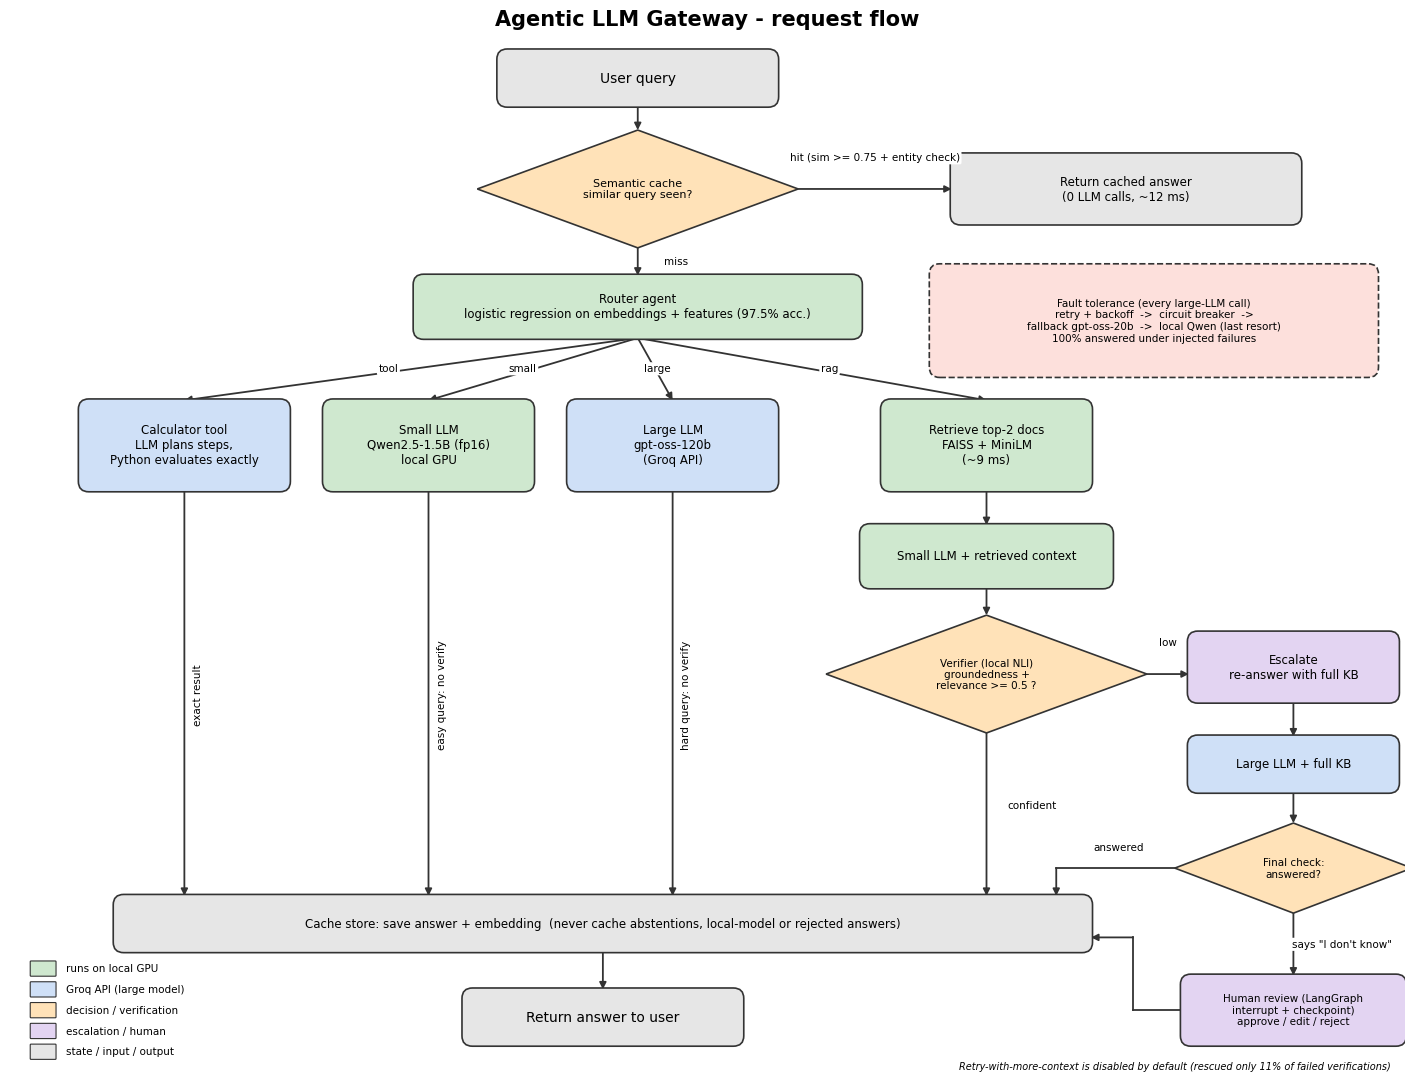

Saved: /content/drive/MyDrive/agentic_llm_gateway/results/assets/architecture_flow.png


In [33]:
# ===== CELL 29: Documentation - request-flow flowchart (how the gateway works) =====
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

ASSETS = f"{RESULTS_DIR}/assets"; os.makedirs(ASSETS, exist_ok=True)
GREEN, BLUE, ORANGE, PURPLE, GREY, RED = "#cfe8cf", "#cfe0f7", "#ffe2b8", "#e3d4f2", "#e6e6e6", "#fde0dc"
EC = "#333333"

fig, ax = plt.subplots(figsize=(18, 13.5))
ax.set_xlim(0, 20); ax.set_ylim(0, 15); ax.axis("off")

def box(x, y, w, h, text, color, fs=8.5, dashed=False):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc=color, ec=EC, lw=1.2, ls="--" if dashed else "-", zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=4)

def diamond(x, y, w, h, text, color, fs=8):
    ax.add_patch(Polygon([(x, y + h/2), (x + w/2, y), (x, y - h/2), (x - w/2, y)], fc=color, ec=EC, lw=1.2, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=4)

def arrow(pts, label=None, lpos=None, fs=7.5):
    for i in range(len(pts) - 2):
        ax.plot([pts[i][0], pts[i+1][0]], [pts[i][1], pts[i+1][1]], color=EC, lw=1.3, zorder=2)
    ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="-|>", color=EC, lw=1.3, shrinkA=0, shrinkB=0), zorder=2)
    if label:
        ax.text(*lpos, label, fontsize=fs, ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))

# ---------------- Entry: cache + router ----------------
box(9, 14.4, 4, 0.8, "User query", GREY, 10)
arrow([(9, 14.0), (9, 13.65)])
diamond(9, 12.8, 4.6, 1.7, "Semantic cache\nsimilar query seen?", ORANGE)
box(16, 12.8, 5, 1.0, "Return cached answer\n(0 LLM calls, ~12 ms)", GREY)
arrow([(11.3, 12.8), (13.5, 12.8)], "hit (sim >= 0.75 + entity check)", (12.4, 13.25))
arrow([(9, 11.95), (9, 11.55)], "miss", (9.55, 11.75))
box(9, 11.1, 6.4, 0.9, "Router agent\nlogistic regression on embeddings + features (97.5% acc.)", GREEN)

# ---------------- Four routes ----------------
paths = [(2.5, "tool",  "Calculator tool\nLLM plans steps,\nPython evaluates exactly", BLUE),
         (6.0, "small", "Small LLM\nQwen2.5-1.5B (fp16)\nlocal GPU", GREEN),
         (9.5, "large", "Large LLM\ngpt-oss-120b\n(Groq API)", BLUE),
         (14.0, "rag",  "Retrieve top-2 docs\nFAISS + MiniLM\n(~9 ms)", GREEN)]
for x, name, text, col in paths:
    box(x, 9.1, 3.0, 1.3, text, col)
    mx, my = 9 + (x - 9) * 0.55, 10.65 - 0.9 * 0.55
    arrow([(9, 10.65), (x, 9.75)], name, (mx, my + 0.05))

# tool / small / large go straight to the cache store (no verification needed)
for x, note in [(2.5, "exact result"), (6.0, "easy query: no verify"), (9.5, "hard query: no verify")]:
    arrow([(x, 8.45), (x, 2.6)])
    ax.text(x + 0.12, 5.5, note, rotation=90, fontsize=7.5, va="center", ha="left", zorder=5)

# ---------------- RAG path + verifier ----------------
arrow([(14, 8.45), (14, 7.95)])
box(14, 7.5, 3.6, 0.9, "Small LLM + retrieved context", GREEN)
arrow([(14, 7.05), (14, 6.65)])
diamond(14, 5.8, 4.6, 1.7, "Verifier (local NLI)\ngroundedness +\nrelevance >= 0.5 ?", ORANGE, 7.5)
arrow([(14, 4.95), (14, 2.6)], "confident", (14.65, 3.9))

# ---------------- Escalation chain ----------------
arrow([(16.3, 5.8), (16.9, 5.8)], "low", (16.6, 6.25))
box(18.4, 5.9, 3.0, 1.0, "Escalate\nre-answer with full KB", PURPLE)
arrow([(18.4, 5.4), (18.4, 4.9)])
box(18.4, 4.5, 3.0, 0.8, "Large LLM + full KB", BLUE)
arrow([(18.4, 4.1), (18.4, 3.65)])
diamond(18.4, 3.0, 3.4, 1.3, "Final check:\nanswered?", ORANGE, 7.5)
arrow([(16.7, 3.0), (15.0, 3.0), (15.0, 2.6)], "answered", (15.9, 3.3))
arrow([(18.4, 2.35), (18.4, 1.45)], "says \"I don't know\"", (19.1, 1.9))
box(18.4, 0.95, 3.2, 1.0, "Human review (LangGraph\ninterrupt + checkpoint)\napprove / edit / reject", PURPLE, 7.5)
arrow([(16.8, 0.95), (16.1, 0.95), (16.1, 2.0), (15.5, 2.0)])

# ---------------- Cache store + output ----------------
box(8.5, 2.2, 14.0, 0.8, "Cache store: save answer + embedding  (never cache abstentions, local-model or rejected answers)", GREY)
arrow([(8.5, 1.8), (8.5, 1.25)])
box(8.5, 0.85, 4.0, 0.8, "Return answer to user", GREY, 10)

# ---------------- Fault tolerance side panel ----------------
box(16.4, 10.9, 6.4, 1.6,
    "Fault tolerance (every large-LLM call)\nretry + backoff  ->  circuit breaker  ->\nfallback gpt-oss-20b  ->  local Qwen (last resort)\n100% answered under injected failures",
    RED, 7.5, dashed=True)

# ---------------- Legend + notes ----------------
for i, (col, lab) in enumerate([(GREEN, "runs on local GPU"), (BLUE, "Groq API (large model)"),
                                (ORANGE, "decision / verification"), (PURPLE, "escalation / human"), (GREY, "state / input / output")]):
    y = 1.55 - i * 0.3
    ax.add_patch(FancyBboxPatch((0.3, y - 0.1), 0.35, 0.2, boxstyle="round,pad=0.01", fc=col, ec=EC, lw=0.8))
    ax.text(0.8, y, lab, fontsize=7.5, va="center")
ax.text(19.8, 0.1, "Retry-with-more-context is disabled by default (rescued only 11% of failed verifications)",
        fontsize=7, ha="right", style="italic")

ax.set_title("Agentic LLM Gateway - request flow", fontsize=15, fontweight="bold", pad=8)
out = f"{ASSETS}/architecture_flow.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", out)